# Tugas Kelompok 3: Pemodelan Topik (RQ1 dan RQ2) Keamanan dan Kebersihan Pangan Program MBG

**Topik:** kekhawatiran publik terhadap keamanan dan kebersihan pangan Program Makan Bergizi Gratis (MBG) di YouTube dan X.

| Pertanyaan penelitian | Analisis di notebook ini |
|---|---|
| **RQ1:** Apa saja jenis permasalahan keamanan dan kebersihan makanan dalam pelaksanaan Program MBG yang muncul dalam diskusi media sosial? | Pemodelan topik dua tingkat (BERTopic), dibandingkan dengan LDA, dievaluasi dengan *topic coherence*, keragaman, stabilitas, dan dokumen representatif |
| **RQ2:** Bagaimana jenis permasalahan tersebut bervariasi antarwilayah di Indonesia? | Distribusi topik per kelompok pulau dan provinsi, uji chi-square, residual terstandar, dan analisis sensitivitas sumber lokasi |

## Gambaran Umum

**Input:** `data/processed/mbg_processed/mbg_processed.csv`, keluaran `rq_preprocessing/TK2_RQ_Preprocessing.ipynb`. Kolom yang dipakai:

| Kolom | Kegunaan |
|---|---|
| `rq1_eligible` | Penanda dokumen layak topic modelling: relevan (menyebut MBG dan kata kunci keamanan pangan), layak pakai, kemunculan pertama teks, dan minimal 3 token |
| `rq1_text_light` | Teks ringan (huruf kecil, tanpa URL/mention/emoji, ejaan baku, tanpa stemming) sebagai input model *embedding* |
| `rq1_tokens` | Token tanpa stopword dan sudah di-stem (Sastrawi) untuk LDA dan representasi kata c-TF-IDF |
| `rq1_issue_categories` | Label lemah berbasis kata kunci, dipakai **hanya** untuk triangulasi, bukan sebagai label topik |
| `rq2_province`, `rq2_island_group`, `rq2_location_source`, `rq2_eligible_text_only` | Lokasi dokumen untuk RQ2 |
| `common_year_month`, `platform`, `doc_type` | Pengelompokan waktu dan platform |

**Output** (folder `analysis/topic_modelling/hasil/`):

| Berkas | Isi |
|---|---|
| `topik_rq1.csv` | Topik per dokumen (`doc_id`, topik level 1 dan 2, label manual, `topic_label`). Kompatibel dengan `analysis/sentimen/tk3_sentimen_rq3.py --topics` |
| `l1_*.csv`, `l2_*.csv`, `lda_*.csv` | Hasil grid search, info topik, dan dokumen representatif |
| `rq2_*.csv`, `tren_*.csv` | Tabel per wilayah, waktu, dan platform |
| `figures/*.png` | Seluruh grafik |
| `konfigurasi_run.json` | Parameter dan versi paket |

### Keputusan desain

1. **Korpus = diskusi publik, tanpa deskripsi video.** RQ menanyakan permasalahan yang muncul dalam *diskusi* media sosial. Deskripsi video adalah teks berita/kanal (panjang, banyak *boilerplate*), sehingga dikeluarkan. Yang dipakai: komentar dan reply YouTube serta post, quote, dan reply X.
2. **BERTopic sebagai model utama, LDA sebagai pembanding.** Teks media sosial pendek (median 12 token), sehingga model berbasis *embedding* lebih cocok daripada model *bag-of-words*. LDA tetap dijalankan sebagai *baseline* dan dievaluasi dengan metrik yang sama.
3. **Pemodelan dua tingkat.** Uji awal menunjukkan bahwa sebagian besar diskusi tidak membahas jenis masalah pangan secara spesifik, tetapi berupa reaksi umum terhadap kasus keracunan atau wacana politik/korupsi. **Level 1** memetakan seluruh diskusi dan memisahkan topik yang membahas masalah keamanan pangan secara spesifik. **Level 2** memodelkan ulang dokumen-dokumen tersebut untuk mendapatkan jenis permasalahan yang lebih rinci. Hasil inilah yang menjawab RQ1 dan RQ2.
4. **Label topik ditentukan manual.** Kata teratas (c-TF-IDF) hanya titik awal. Setiap topik diberi label setelah membaca dokumen terdekat ke centroid dan sampel acak dokumen. Label disertai **kata jangkar** yang diverifikasi otomatis sehingga notebook akan berhenti bila hasil model berubah dan label tidak lagi sesuai.
5. **Evaluasi kuantitatif:** *topic coherence* NPMI dan C_V (Röder dkk., 2015), *topic diversity* (Dieng dkk., 2020), dan stabilitas klaster antar-*seed* (Adjusted Rand Index). Coherence dihitung sendiri karena `gensim` belum tersedia untuk Python 3.15. Ko-okurensi dihitung pada tingkat dokumen; untuk teks pendek, ini setara dengan jendela geser C_V standar.

# 1. Persiapan

In [1]:
import json
import platform as py_platform
import textwrap
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import bertopic
import sentence_transformers
import sklearn
import torch
import umap
from bertopic import BERTopic
from bertopic.dimensionality import BaseDimensionalityReduction
from bertopic.vectorizers import ClassTfidfTransformer
from umap import UMAP

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_PATH = ROOT / "data/processed/mbg_processed/mbg_processed.csv"
OUT = ROOT / "analysis/topic_modelling/hasil"
FIG = OUT / "figures"
CACHE = OUT / "cache"
for p in (OUT, FIG, CACHE):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
STABILITY_SEEDS = [1, 2, 3]
EMB_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
UMAP_PARAMS = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
TOP_N = 10

print("Root          :", ROOT)
print("Python        :", py_platform.python_version())
for m in (pd, np, sklearn, bertopic, sentence_transformers, umap, torch):
    print(f"{m.__name__:<22}: {m.__version__}")

/Users/macbookair/Documents/TK Anmedsos/mbg-social-analytics/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1125 23:42:02.358000 34327 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Root          : /Users/macbookair/Documents/TK Anmedsos/mbg-social-analytics
Python        : 3.15.0
pandas                : 3.1.1
numpy                 : 2.5.5
sklearn               : 1.9.1
bertopic              : 0.17.4
sentence_transformers : 6.3.0
umap                  : 0.6.0
torch                 : 2.15.0


In [2]:
def savefig(name):
    plt.savefig(FIG / name)
    plt.show()


def short(text, width=260):
    return textwrap.shorten(str(text).replace("\n", " "), width=width, placeholder=" …")

# 2. Memuat Data dan Menentukan Korpus

In [3]:
COLS = [
    "doc_id", "platform", "doc_type", "rq1_eligible", "rq1_text_light", "rq1_tokens",
    "rq1_n_tokens", "rq1_issue_categories", "rq2_eligible", "rq2_eligible_text_only",
    "rq2_province", "rq2_island_group", "rq2_location_source", "common_year_month", "context_id",
]
t0 = time.time()
raw = pd.read_csv(DATA_PATH, usecols=COLS, low_memory=False)
print(f"Dataset: {len(raw):,} baris dimuat dalam {time.time() - t0:.1f} detik")

eligible = raw[raw["rq1_eligible"] == True]
docs = eligible[eligible["doc_type"] != "video"].reset_index(drop=True)
del raw

summary = (
    eligible.assign(korpus=np.where(eligible["doc_type"] == "video", "dikeluarkan (video)", "dipakai"))
    .groupby(["korpus", "platform", "doc_type"]).size().rename("dokumen").reset_index()
)
display(summary)
print(f"Korpus topic modelling: {len(docs):,} dokumen "
      f"(YouTube {(docs.platform == 'youtube').sum():,}; X {(docs.platform == 'x').sum():,})")
print("Statistik jumlah token:", docs["rq1_n_tokens"].describe().round(1).to_dict())

Dataset: 669,383 baris dimuat dalam 1.4 detik


,korpus,platform,doc_type,dokumen
0,dikeluarkan (video),youtube,video,2880
1,dipakai,x,post,7054
2,dipakai,x,quote,1767
3,dipakai,x,reply,5395
4,dipakai,youtube,comment,41173
5,dipakai,youtube,reply,5106


Korpus topic modelling: 60,495 dokumen (YouTube 46,279; X 14,216)
Statistik jumlah token: {'count': 60495.0, 'mean': 19.3, 'std': 34.8, 'min': 3.0, '25%': 7.0, '50%': 12.0, '75%': 20.0, 'max': 911.0}


Korpus terdiri dari dokumen `rq1_eligible` **tanpa deskripsi video**. Dokumennya pendek (median 12 token), sehingga sinyal ko-okurensi kata per dokumen lemah. Inilah alasan utama memakai model berbasis *embedding*: kemiripan makna dapat ditangkap walaupun dua dokumen tidak berbagi kata yang sama.

## 2.1. Embedding Dokumen

Embedding dibuat dari `rq1_text_light` dengan `paraphrase-multilingual-MiniLM-L12-v2`, model *sentence-transformers* multibahasa (termasuk bahasa Indonesia) yang ringan dan umum dipakai sebagai embedding default BERTopic untuk bahasa non-Inggris. Panjang maksimum 128 token cukup untuk teks media sosial; teks yang lebih panjang (sebagian post X) dipotong. Hasilnya disimpan di cache agar notebook dapat dijalankan ulang tanpa menghitung ulang.

In [4]:
emb_file, ids_file = CACHE / "embeddings_minilm.npy", CACHE / "embeddings_minilm_ids.csv"
if emb_file.exists() and ids_file.exists() and pd.read_csv(ids_file)["doc_id"].tolist() == docs["doc_id"].tolist():
    EMB = np.load(emb_file)
    print("Embedding dimuat dari cache:", EMB.shape)
else:
    from sentence_transformers import SentenceTransformer
    device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
    encoder = SentenceTransformer(EMB_MODEL, device=device)
    t0 = time.time()
    EMB = encoder.encode(docs["rq1_text_light"].tolist(), batch_size=128, normalize_embeddings=True,
                         convert_to_numpy=True, show_progress_bar=True).astype(np.float32)
    np.save(emb_file, EMB)
    docs[["doc_id"]].to_csv(ids_file, index=False)
    print(f"Embedding dihitung di {device} dalam {time.time() - t0:.0f} detik:", EMB.shape)

Embedding dimuat dari cache: (60495, 384)


## 2.2. Metrik Evaluasi Topik

| Metrik | Definisi | Interpretasi |
|---|---|---|
| **NPMI** | Rata-rata *normalized pointwise mutual information* antarpasangan 10 kata teratas topik, dihitung dari ko-okurensi dalam dokumen korpus | −1 (tidak pernah muncul bersama) sampai 1 (selalu bersama); makin tinggi makin koheren |
| **C_V** | Kemiripan kosinus antara vektor NPMI tiap kata teratas dan vektor NPMI seluruh kata topik (Röder dkk., 2015) | 0 sampai 1; berkorelasi paling baik dengan penilaian manusia |
| **Diversity** | Proporsi kata unik di antara 10 kata teratas semua topik | 1 = tidak ada kata yang berulang antartopik |
| **Stabilitas (ARI)** | Rata-rata Adjusted Rand Index penugasan topik antara *seed* utama dan 3 *seed* lain | 1 = klaster identik; menguji apakah topik bukan artefak inisialisasi |

Kosakata evaluasi dibuat dari `rq1_tokens` dengan `min_df` 10 dan `max_df` 0,5. Kata yang muncul di lebih dari separuh dokumen dibuang karena tidak membedakan topik; dalam korpus ini kata tersebut adalah `racun`, yang ada di 68% dokumen. Kosakata yang sama dipakai sebagai representasi kata BERTopic dan sebagai input LDA, sehingga coherence kedua model dihitung pada korpus referensi yang sama dan dapat dibandingkan langsung.

In [5]:
def build_vocab(tokens, min_df, max_df=0.5):
    cv = CountVectorizer(token_pattern=r"\S+", min_df=min_df, max_df=max_df, binary=True)
    X = cv.fit_transform(tokens).tocsc()
    return cv.get_feature_names_out(), X


class Coherence:
    # NPMI dan C_V dengan ko-okurensi tingkat dokumen (korpus referensi biner)
    def __init__(self, X_binary, vocab):
        self.X, self.N = X_binary, X_binary.shape[0]
        self.idx = {w: i for i, w in enumerate(vocab)}
        self.df = np.asarray(X_binary.sum(0)).ravel()

    def npmi_matrix(self, words):
        ids = [self.idx[w] for w in words if w in self.idx]
        sub = self.X[:, ids]
        co = (sub.T @ sub).toarray().astype(float)
        p = self.df[ids] / self.N
        pij = co / self.N
        eps = 1e-12
        npmi = np.log((pij + eps) / np.outer(p, p)) / (-np.log(pij + eps))
        npmi[co == 0] = -1.0
        np.fill_diagonal(npmi, 1.0)
        return npmi

    def npmi(self, words):
        M = self.npmi_matrix(words)
        return M[np.triu_indices(len(M), 1)].mean()

    def cv(self, words):
        M = self.npmi_matrix(words)
        total = M.sum(0)
        return ((M @ total) / (np.linalg.norm(M, axis=1) * np.linalg.norm(total) + 1e-12)).mean()


def diversity(topic_words):
    flat = [w for ws in topic_words for w in ws]
    return len(set(flat)) / len(flat)


def evaluate(topic_words, coh):
    return dict(
        npmi=np.mean([coh.npmi(w) for w in topic_words]),
        c_v=np.mean([coh.cv(w) for w in topic_words]),
        diversity=diversity(topic_words),
    )


VOCAB1, XB1 = build_vocab(docs["rq1_tokens"], min_df=10)
COH1 = Coherence(XB1, VOCAB1)
print(f"Kosakata level 1: {len(VOCAB1):,} token")

Kosakata level 1: 6,009 token


In [6]:
def fit_bertopic(token_docs, reduced, cluster_model, vocab):
    # UMAP sudah dihitung di luar (reduced), sehingga grid search cukup mengulang clustering
    model = BERTopic(
        umap_model=BaseDimensionalityReduction(),
        hdbscan_model=cluster_model,
        vectorizer_model=CountVectorizer(token_pattern=r"\S+", vocabulary=vocab),
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=TOP_N,
    )
    topics, _ = model.fit_transform(list(token_docs), embeddings=reduced)
    return model, np.asarray(topics)


def topic_words(model, k):
    return [w for w, _ in model.get_topic(k)][:TOP_N]


def topic_table(model, topics, frame, coh):
    rows = []
    for k in sorted(set(topics) - {-1}):
        m = topics == k
        words = topic_words(model, k)
        rows.append(dict(topic=k, n_docs=int(m.sum()), share=m.mean(),
                         share_x=(frame.loc[m, "platform"] == "x").mean(),
                         npmi=coh.npmi(words), c_v=coh.cv(words), top_words=" ".join(words)))
    return pd.DataFrame(rows)


def representative_docs(topics, emb, texts, k, n_near=4, n_rand=3, seed=SEED):
    # dokumen terdekat ke centroid embedding topik + sampel acak (agar tidak hanya melihat prototipe)
    idx = np.where(topics == k)[0]
    centroid = emb[idx].mean(0)
    sim = emb[idx] @ centroid / np.linalg.norm(centroid)
    near = idx[np.argsort(-sim)[:n_near]]
    pool = np.setdiff1d(idx, near)
    rnd = np.random.default_rng(seed).choice(pool, min(n_rand, len(pool)), replace=False)
    return [("centroid", texts[i]) for i in near] + [("acak", texts[i]) for i in rnd]


def print_representatives(model, topics, emb, texts, labels=None):
    rows = []
    for k in sorted(set(topics) - {-1}):
        head = f"Topik {k} (n={int((topics == k).sum()):,})"
        if labels:
            head += f" | {labels[k][0]}"
        print(f"\n### {head}\n    kata: {' '.join(topic_words(model, k))}")
        for kind, t in representative_docs(topics, emb, texts, k):
            print(f"    [{kind}] {short(t)}")
            rows.append(dict(topic=k, jenis=kind, teks=t))
    return pd.DataFrame(rows)


def check_labels(model, topics, labels):
    missing = sorted(set(topics) - {-1} - set(labels))
    assert not missing, f"Topik belum berlabel: {missing}"
    bad = {k: (v[2], topic_words(model, k)) for k, v in labels.items() if v[2] not in topic_words(model, k)}
    assert not bad, f"Kata jangkar tidak ada di kata teratas, periksa ulang label manual: {bad}"
    print(f"OK: {len(labels)} label manual cocok dengan kata jangkar masing-masing topik.")


def kmeans_stability(reduced, k, base_labels):
    return np.mean([adjusted_rand_score(base_labels, KMeans(n_clusters=k, random_state=s, n_init=10).fit_predict(reduced))
                    for s in STABILITY_SEEDS])

# 3. Level 1: Pemetaan Seluruh Diskusi (BERTopic)

Pipeline BERTopic: **embedding** (bagian 2.1) → **UMAP** (5 dimensi, `n_neighbors` 15, `min_dist` 0, kosinus) → **clustering** → **c-TF-IDF** (`reduce_frequent_words=True` agar kata yang ada di hampir semua topik diredam) untuk memilih kata representatif. UMAP dihitung sekali, lalu hanya tahap clustering yang divariasikan.

In [7]:
t0 = time.time()
R1 = UMAP(**UMAP_PARAMS).fit_transform(EMB)
print(f"UMAP level 1: {R1.shape} dalam {time.time() - t0:.0f} detik")

UMAP level 1: (60495, 5) dalam 40 detik


## 3.1. Pemilihan Algoritma Clustering: HDBSCAN vs K-Means

Konfigurasi default BERTopic memakai HDBSCAN, yang menentukan jumlah topik secara otomatis dan menandai dokumen *outlier* (topik −1). Keduanya diuji pada beberapa `min_cluster_size` dan dibandingkan dengan K-Means.

In [8]:
hdb_rows = []
for mcs, method in [(50, "eom"), (100, "eom"), (150, "eom"), (200, "eom"), (150, "leaf"), (300, "leaf")]:
    model, t = fit_bertopic(docs["rq1_tokens"], R1, HDBSCAN(min_cluster_size=mcs, min_samples=10,
                                                             cluster_selection_method=method), VOCAB1)
    ks = sorted(set(t) - {-1})
    sizes = np.bincount(t[t >= 0])
    hdb_rows.append(dict(algoritma=f"HDBSCAN {method}", parameter=f"min_cluster_size={mcs}", n_topik=len(ks),
                         outlier=(t == -1).mean(), topik_terbesar=sizes.max() / len(t),
                         **evaluate([topic_words(model, k) for k in ks], COH1)))
for k in (20, 30):
    model, t = fit_bertopic(docs["rq1_tokens"], R1, KMeans(n_clusters=k, random_state=SEED, n_init=10), VOCAB1)
    hdb_rows.append(dict(algoritma="K-Means", parameter=f"K={k}", n_topik=k, outlier=0.0,
                         topik_terbesar=np.bincount(t).max() / len(t),
                         **evaluate([topic_words(model, j) for j in range(k)], COH1)))
cluster_cmp = pd.DataFrame(hdb_rows)
cluster_cmp.to_csv(OUT / "l1_perbandingan_clustering.csv", index=False)
cluster_cmp.round(3)

,algoritma,parameter,n_topik,outlier,topik_terbesar,npmi,c_v,diversity
0,HDBSCAN eom,min_cluster_size=50,100,0.520,0.056,-0.179,0.548,0.836
1,HDBSCAN eom,min_cluster_size=100,58,0.535,0.056,-0.036,0.580,0.850
2,HDBSCAN eom,min_cluster_size=150,32,0.399,0.246,0.069,0.592,0.812
3,HDBSCAN eom,min_cluster_size=200,2,0.001,0.971,0.136,0.577,1.000
4,HDBSCAN leaf,min_cluster_size=150,48,0.622,0.026,0.011,0.580,0.794
5,HDBSCAN leaf,min_cluster_size=300,31,0.643,0.030,0.147,0.654,0.774
6,K-Means,K=20,20,0.000,0.086,0.194,0.670,0.740
7,K-Means,K=30,30,0.000,0.076,0.217,0.677,0.710


**Pengamatan:**

- **HDBSCAN membuang 40–64% dokumen sebagai outlier**, karena diskusi media sosial tentang MBG sangat kontinu dan tidak membentuk klaster padat yang terpisah jelas. Untuk RQ2 hal ini merugikan, karena separuh dokumen berlokasi akan hilang.
- **HDBSCAN `eom` tidak stabil terhadap parameter.** Pada `min_cluster_size` ≥ 200, hampir seluruh dokumen runtuh menjadi satu klaster raksasa (topik terbesar ≈ 95%).
- **K-Means** menugaskan semua dokumen, menghasilkan NPMI dan C_V yang lebih tinggi, dan jumlah topiknya dapat dijustifikasi secara eksplisit lewat grid search K. Cara ini sejalan dengan LDA, yang juga memerlukan K.

Karena itu, **K-Means dipakai sebagai komponen clustering BERTopic**. Opsi ini didukung resmi oleh BERTopic dengan mengganti `hdbscan_model`.

## 3.2. Menentukan Jumlah Topik (K) Level 1

,K,npmi,c_v,diversity,stabilitas_ari,topik_terbesar
0,10,0.149,0.629,0.800,0.980,0.169
1,15,0.192,0.676,0.793,0.860,0.165
2,20,0.194,0.670,0.740,0.891,0.086
3,25,0.192,0.666,0.744,0.911,0.076
4,30,0.217,0.677,0.710,0.815,0.076
5,35,0.213,0.681,0.794,0.804,0.065
6,40,0.200,0.665,0.752,0.804,0.045


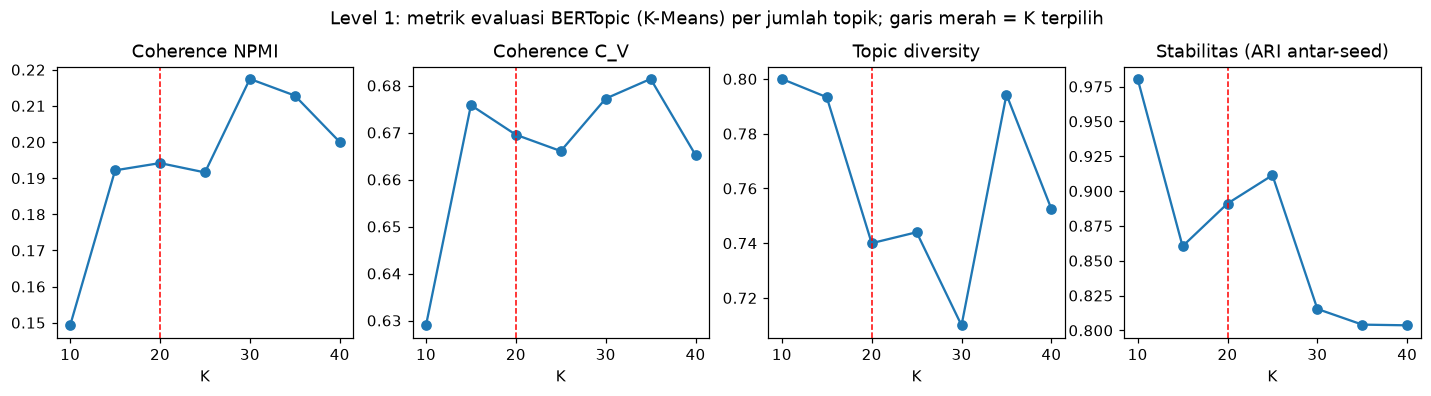

In [9]:
K_GRID_L1 = [10, 15, 20, 25, 30, 35, 40]
rows = []
for k in K_GRID_L1:
    model, t = fit_bertopic(docs["rq1_tokens"], R1, KMeans(n_clusters=k, random_state=SEED, n_init=10), VOCAB1)
    rows.append(dict(K=k, **evaluate([topic_words(model, j) for j in range(k)], COH1),
                     stabilitas_ari=kmeans_stability(R1, k, t), topik_terbesar=np.bincount(t).max() / len(t)))
grid_l1 = pd.DataFrame(rows)
grid_l1.to_csv(OUT / "l1_grid_k.csv", index=False)
display(grid_l1.round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col, title in zip(axes, ["npmi", "c_v", "diversity", "stabilitas_ari"],
                          ["Coherence NPMI", "Coherence C_V", "Topic diversity", "Stabilitas (ARI antar-seed)"]):
    ax.plot(grid_l1["K"], grid_l1[col], marker="o")
    ax.axvline(20, color="red", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("K")
fig.suptitle("Level 1: metrik evaluasi BERTopic (K-Means) per jumlah topik; garis merah = K terpilih", y=1.04)
savefig("l1_grid_k.png")

**Justifikasi K = 20.** Coherence (NPMI dan C_V) naik tajam dari K = 10 ke K = 15–20, lalu mendatar; kenaikan kecil pada K = 30 dibayar dengan turunnya diversity (kata teratas mulai berulang antartopik) dan stabilitas. Pada K = 20, coherence sudah mendekati maksimum, diversity masih di atas 0,7, dan stabilitas tetap tinggi. Selain itu, tujuan level 1 adalah **pemetaan kasar** untuk memisahkan topik masalah keamanan pangan dari wacana lain, sehingga resolusi 20 topik sudah cukup. Rincian jenis masalah dicari di level 2.

In [10]:
K_L1 = 20
MODEL1, T1 = fit_bertopic(docs["rq1_tokens"], R1, KMeans(n_clusters=K_L1, random_state=SEED, n_init=10), VOCAB1)
info1 = topic_table(MODEL1, T1, docs, COH1)
print("Evaluasi model level 1:", {k: round(v, 3) for k, v in evaluate([topic_words(MODEL1, k) for k in range(K_L1)], COH1).items()})
info1.round(3)

Evaluasi model level 1: {'npmi': np.float64(0.194), 'c_v': np.float64(0.67), 'diversity': 0.74}


,topic,n_docs,share,share_x,npmi,c_v,top_words
0,0,5179,0.086,0.180,0.109,0.579,anak tua bangsa korban generasi nyawa stop takut cucu biar
1,1,5169,0.085,0.179,0.194,0.740,korupsi uang anggar duit rakyat koruptor pajak perintah negara harga
2,2,4915,0.081,0.343,0.267,0.720,september kasus korban sangka april berita hukum mei agustus februari
3,3,4888,0.081,0.242,0.161,0.682,guru siswa sekolah murid tolak ajar siswi tua korban pihak
4,4,4324,0.071,0.166,0.010,0.376,tikus bahan nama gas basi sengaja masak malah aneh omon
5,5,4243,0.070,0.120,0.053,0.442,maaf sabotase sengaja prabowo mana otak biar malah minta moga
6,6,3340,0.055,0.224,0.173,0.697,sekolah masak kantin dapur basi jam masing tua murid bawa
7,7,3289,0.054,0.189,0.203,0.753,presiden politik prabowo pimpin rakyat menteri bangsa negara partai jabat
8,8,3139,0.052,0.207,0.226,0.733,bakteri masak dapur jam bersih panas suhu bahan malam nitrit
9,9,2941,0.049,0.147,0.125,0.579,hambar ayam plastik basi ikan sayur buah rasa enak micin


## 3.3. Interpretasi Topik Level 1: Kata dan Dokumen Representatif

Untuk setiap topik ditampilkan 10 kata teratas (c-TF-IDF), **4 dokumen terdekat ke centroid** embedding topik, dan **3 dokumen acak**. Dokumen acak penting untuk mengecek apakah topik juga konsisten di luar prototipenya.

In [11]:
rep1 = print_representatives(MODEL1, T1, EMB, docs["rq1_text_light"].values)


### Topik 0 (n=5,179)
    kata: anak tua bangsa korban generasi nyawa stop takut cucu biar
    [centroid] diuangkan saja,karena anak2 keracunan ,tidak sehat mknya,
    [centroid] betul mbg di bubarkan anak2 banyak keracunan
    [centroid] pada enak"an makan uang mbg tapi anak anak pada keracunan!
    [centroid] sesalkan tidak perlu , anak anak sudah keracunan. enak saja jawabnya
    [acak] anak bisa sarapan ko d rumah .makan siang nya beda seperti roti telor rebus buah2 han dan susu gkakan bklan ada keracunan
    [acak] yang bagian pengawasan bagaimana sih masak sudah dikasih ke anak bisa keracunan kan bisa dicoba dulu basi apa g makanannya baru deh,kalau basi g usah diganti uangnya
    [acak] kasih uang saja ke ortunya pak.karena didunia tidak ada orang tua yang ingin meracuni anaknya...

### Topik 1 (n=5,169)
    kata: korupsi uang anggar duit rakyat koruptor pajak perintah negara harga
    [centroid] bukan masalah membutuhkan makan mbgnya masalahnya banyak yang keracunan bukan tiga

## 3.4. Label Manual Level 1

Label disusun dari pembacaan kata dan dokumen di atas, **bukan** dari label otomatis model. Setiap topik kemudian dikelompokkan ke dalam empat kelompok wacana:

| Kelompok | Kriteria |
|---|---|
| **Masalah keamanan & kebersihan pangan spesifik** | Dokumen menyebut *apa* masalahnya: kondisi makanan (basi, busuk, belatung, rasa), proses di dapur, jam masak, higiene, bakteri, standar/sertifikasi, atau laporan kasus beserta gejalanya |
| **Reaksi umum terhadap kasus keracunan** | Menyebut keracunan, tetapi isinya kemarahan, kekhawatiran, plesetan "makan beracun gratis", atau tuntutan penghentian, tanpa rincian masalah |
| **Wacana politik, tata kelola & anggaran** | Fokus pada presiden, korupsi, anggaran, pejabat BGN, atau alternatif program |
| **Noise / umpatan** | Umpatan pendek yang tidak membahas MBG secara substantif |

Kolom ketiga dalam kamus label adalah **kata jangkar**, yaitu kata yang harus ada di 10 kata teratas topik. Kata ini dicek otomatis agar label tidak tertukar bila hasil model berubah.

In [12]:
G_FS = "Masalah keamanan & kebersihan pangan spesifik"
G_GEN = "Reaksi umum terhadap kasus keracunan"
G_POL = "Wacana politik, tata kelola & anggaran"
G_NOISE = "Noise / umpatan"
L1_GROUPS = [G_FS, G_GEN, G_POL, G_NOISE]

L1_LABELS = {
    0: ("Anak sebagai korban dan kekhawatiran orang tua", G_GEN, "anak"),
    1: ("Korupsi anggaran dan makanan 'beracun'", G_POL, "korupsi"),
    2: ("Jumlah korban dan tuntutan usut tuntas", G_GEN, "korban"),
    3: ("Siswa dan guru keracunan di sekolah", G_GEN, "siswa"),
    4: ("Plesetan 'makanan beracun gratis'", G_GEN, "nama"),
    5: ("Komentar pendek: sarkasme, permintaan maaf, dugaan sabotase", G_GEN, "sengaja"),
    6: ("Usulan dapur/kantin sekolah dan jarak distribusi", G_FS, "kantin"),
    7: ("Presiden, politik, dan pejabat", G_POL, "presiden"),
    8: ("Dapur SPPG, proses masak, dan penyebab keracunan", G_FS, "bakteri"),
    9: ("Kondisi makanan: basi, hambar, busuk, wadah", G_FS, "hambar"),
    10: ("Pengalihan dana MBG (pendidikan, uang tunai)", G_POL, "dana"),
    11: ("Umpatan dan kata 'busuk/bau' kiasan", G_NOISE, "otak"),
    12: ("Tanggung jawab hukum dan dugaan sabotase", G_GEN, "hukum"),
    13: ("Nasib generasi dan negara", G_POL, "indonesia"),
    14: ("Laporan kasus keracunan massal dan gejalanya", G_FS, "duga"),
    15: ("Pengalaman menu: alergi, susu, nasi, rasa", G_FS, "alergi"),
    16: ("Kompetensi kepala BGN ('ahli serangga') dan menu serangga", G_POL, "serangga"),
    17: ("Korupsi dan desakan menghentikan program", G_POL, "ilustrasi"),
    18: ("Standar dan sertifikasi higiene (SLHS) SPPG", G_FS, "standar"),
    19: ("Rekap daftar kasus keracunan per daerah", G_FS, "tulungagung"),
}
check_labels(MODEL1, T1, L1_LABELS)

docs["l1_topic"] = T1
docs["l1_label"] = docs["l1_topic"].map(lambda k: L1_LABELS[k][0])
docs["l1_group"] = docs["l1_topic"].map(lambda k: L1_LABELS[k][1])
info1["label"] = info1["topic"].map(lambda k: L1_LABELS[k][0])
info1["kelompok"] = info1["topic"].map(lambda k: L1_LABELS[k][1])
info1.to_csv(OUT / "l1_info_topik.csv", index=False)
rep1.assign(label=rep1["topic"].map(lambda k: L1_LABELS[k][0])).to_csv(OUT / "l1_dokumen_representatif.csv", index=False)
info1[["topic", "label", "kelompok", "n_docs", "share", "share_x", "npmi", "c_v", "top_words"]].round(3)

OK: 20 label manual cocok dengan kata jangkar masing-masing topik.


,topic,label,kelompok,n_docs,share,share_x,npmi,c_v,top_words
0,0,Anak sebagai korban dan kekhawatiran orang tua,Reaksi umum terhadap kasus keracunan,5179,0.086,0.180,0.109,0.579,anak tua bangsa korban generasi nyawa stop takut cucu biar
1,1,Korupsi anggaran dan makanan 'beracun',"Wacana politik, tata kelola & anggaran",5169,0.085,0.179,0.194,0.740,korupsi uang anggar duit rakyat koruptor pajak perintah negara harga
2,2,Jumlah korban dan tuntutan usut tuntas,Reaksi umum terhadap kasus keracunan,4915,0.081,0.343,0.267,0.720,september kasus korban sangka april berita hukum mei agustus februari
3,3,Siswa dan guru keracunan di sekolah,Reaksi umum terhadap kasus keracunan,4888,0.081,0.242,0.161,0.682,guru siswa sekolah murid tolak ajar siswi tua korban pihak
4,4,Plesetan 'makanan beracun gratis',Reaksi umum terhadap kasus keracunan,4324,0.071,0.166,0.010,0.376,tikus bahan nama gas basi sengaja masak malah aneh omon
5,5,"Komentar pendek: sarkasme, permintaan maaf, dugaan sabotase",Reaksi umum terhadap kasus keracunan,4243,0.070,0.120,0.053,0.442,maaf sabotase sengaja prabowo mana otak biar malah minta moga
6,6,Usulan dapur/kantin sekolah dan jarak distribusi,Masalah keamanan & kebersihan pangan spesifik,3340,0.055,0.224,0.173,0.697,sekolah masak kantin dapur basi jam masing tua murid bawa
7,7,"Presiden, politik, dan pejabat","Wacana politik, tata kelola & anggaran",3289,0.054,0.189,0.203,0.753,presiden politik prabowo pimpin rakyat menteri bangsa negara partai jabat
8,8,"Dapur SPPG, proses masak, dan penyebab keracunan",Masalah keamanan & kebersihan pangan spesifik,3139,0.052,0.207,0.226,0.733,bakteri masak dapur jam bersih panas suhu bahan malam nitrit
9,9,"Kondisi makanan: basi, hambar, busuk, wadah",Masalah keamanan & kebersihan pangan spesifik,2941,0.049,0.147,0.125,0.579,hambar ayam plastik basi ikan sayur buah rasa enak micin


,dokumen,proporsi
l1_group,,
Masalah keamanan & kebersihan pangan spesifik,14651,0.242
Reaksi umum terhadap kasus keracunan,26194,0.433
"Wacana politik, tata kelola & anggaran",16957,0.280
Noise / umpatan,2693,0.045


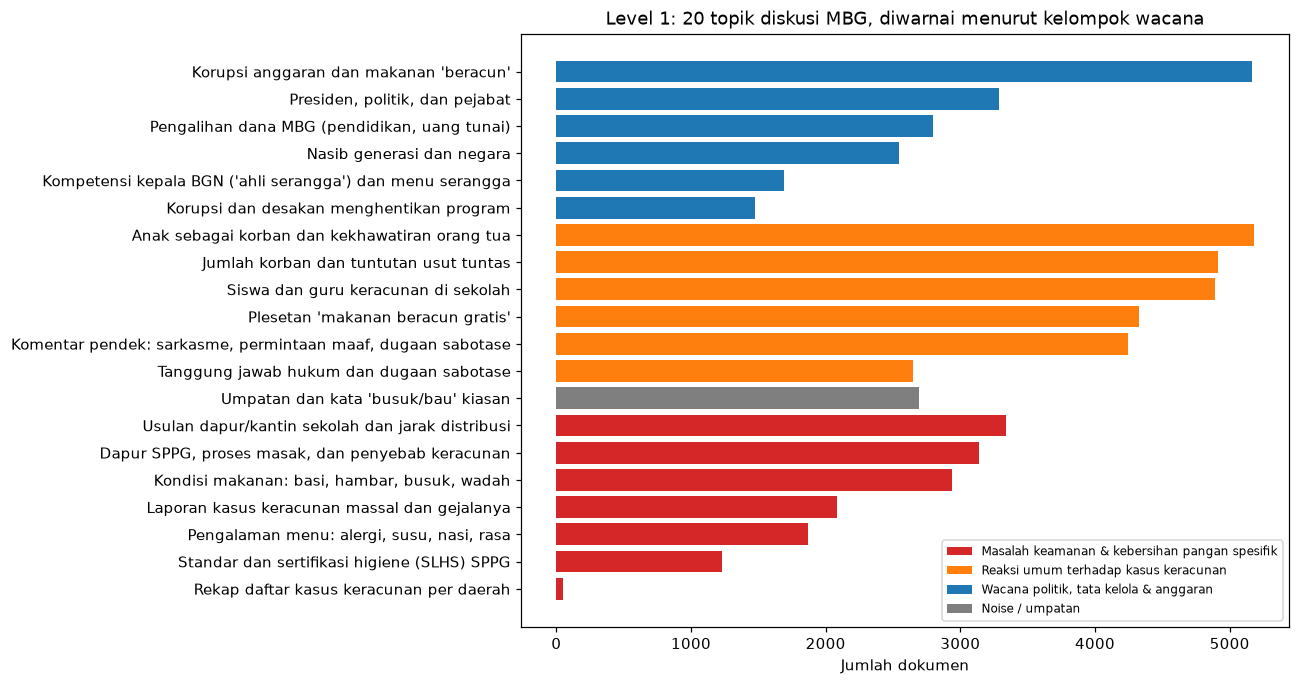

In [13]:
grp = docs["l1_group"].value_counts().reindex(L1_GROUPS)
display(pd.DataFrame({"dokumen": grp, "proporsi": (grp / grp.sum()).round(3)}))

plot = info1.sort_values(["kelompok", "n_docs"], ascending=[True, True])
colors = dict(zip(L1_GROUPS, ["#d62728", "#ff7f0e", "#1f77b4", "#7f7f7f"]))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot["label"], plot["n_docs"], color=plot["kelompok"].map(colors))
for g, c in colors.items():
    ax.bar(0, 0, color=c, label=g)
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("Jumlah dokumen")
ax.set_title("Level 1: 20 topik diskusi MBG, diwarnai menurut kelompok wacana")
savefig("l1_topik_kelompok.png")

**Interpretasi level 1.** Diskusi publik yang lolos filter relevansi didominasi oleh **reaksi umum terhadap kasus keracunan** dan **wacana politik/korupsi**. Hanya sekitar seperempat dokumen yang membahas masalah keamanan pangan **secara spesifik**: kondisi makanan, dapur dan proses masak, standar higiene, alergi/menu, serta laporan dan rekap kasus. Ini penting untuk RQ1: menghitung kata "keracunan" saja tidak cukup untuk mengetahui *jenis* permasalahannya, karena sebagian besar penyebutannya bersifat emosional atau politis. Tujuh topik pada kelompok pertama (merah) menjadi korpus level 2.

Beberapa topik perlu dicatat:
- Topik 16 tampak seperti "benda asing/serangga", tetapi dokumennya kebanyakan menyindir latar belakang kepala BGN sebagai ahli serangga dan wacana menu serangga, bukan temuan serangga di makanan. Karena itu topik ini dimasukkan ke wacana politik/tata kelola.
- Topik 17 memiliki kata teratas yang kurang informatif ("ilustrasi", "insiden"), tetapi dokumennya konsisten membahas korupsi dan desakan penghentian program. Ini contoh mengapa label tidak dapat diambil langsung dari kata teratas.

# 4. Pembanding: LDA

LDA (Latent Dirichlet Allocation, `sklearn`, *online variational Bayes*) dijalankan pada `rq1_tokens` dengan kosakata yang sama (`min_df` 10, `max_df` 0,5) dan dievaluasi dengan coherence pada korpus referensi yang sama, sehingga perbandingannya setara.

Grid LDA selesai dalam 294 detik


,K,npmi,c_v,diversity,perplexity,topik_terbesar
0,5,0.135,0.621,0.820,1289.622,0.366
1,10,0.185,0.683,0.870,1364.633,0.220
2,15,0.162,0.669,0.853,1403.692,0.146
3,20,0.137,0.629,0.840,1434.295,0.127
4,25,0.171,0.657,0.864,1496.245,0.113
5,30,0.151,0.641,0.850,1567.340,0.082
6,40,0.131,0.611,0.885,1685.579,0.071


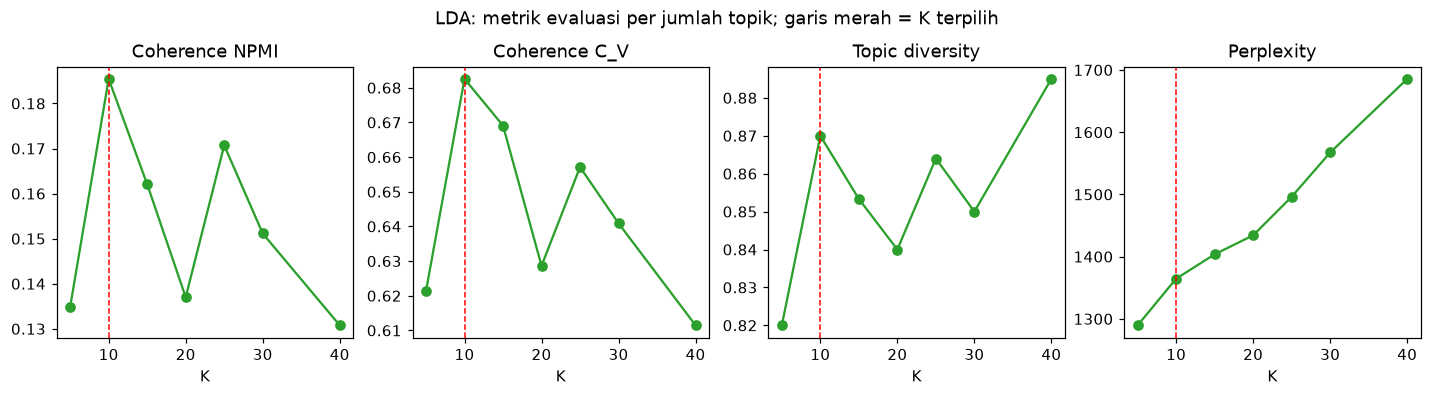

In [14]:
XC1 = CountVectorizer(token_pattern=r"\S+", vocabulary=VOCAB1).fit_transform(docs["rq1_tokens"])


def fit_lda(k, seed=SEED):
    lda = LatentDirichletAllocation(n_components=k, learning_method="online", batch_size=2048,
                                    max_iter=20, random_state=seed, n_jobs=-1).fit(XC1)
    words = [[VOCAB1[i] for i in comp.argsort()[::-1][:TOP_N]] for comp in lda.components_]
    return lda, words


rows = []
t0 = time.time()
for k in [5, 10, 15, 20, 25, 30, 40]:
    lda, words = fit_lda(k)
    dom = lda.transform(XC1).argmax(1)
    rows.append(dict(K=k, **evaluate(words, COH1), perplexity=lda.perplexity(XC1),
                     topik_terbesar=np.bincount(dom, minlength=k).max() / len(dom)))
grid_lda = pd.DataFrame(rows)
grid_lda.to_csv(OUT / "lda_grid_k.csv", index=False)
print(f"Grid LDA selesai dalam {time.time() - t0:.0f} detik")
display(grid_lda.round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col, title in zip(axes, ["npmi", "c_v", "diversity", "perplexity"],
                          ["Coherence NPMI", "Coherence C_V", "Topic diversity", "Perplexity"]):
    ax.plot(grid_lda["K"], grid_lda[col], marker="o", color="tab:green")
    ax.axvline(10, color="red", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("K")
fig.suptitle("LDA: metrik evaluasi per jumlah topik; garis merah = K terpilih", y=1.04)
savefig("lda_grid_k.png")

In [15]:
K_LDA = 10
LDA, LDA_WORDS = fit_lda(K_LDA)
theta = LDA.transform(XC1)
docs["lda_topic"] = theta.argmax(1)
lda_info = pd.DataFrame({
    "topic": range(K_LDA),
    "n_docs_dominan": np.bincount(docs["lda_topic"], minlength=K_LDA),
    "npmi": [COH1.npmi(w) for w in LDA_WORDS],
    "c_v": [COH1.cv(w) for w in LDA_WORDS],
    "top_words": [" ".join(w) for w in LDA_WORDS],
})
lda_info.to_csv(OUT / "lda_info_topik.csv", index=False)
display(lda_info.round(3))

# dokumen dengan bobot topik tertinggi per topik LDA
for k in range(K_LDA):
    top = np.argsort(-theta[:, k])[:3]
    print(f"\n### LDA topik {k}: {' '.join(LDA_WORDS[k])}")
    for i in top:
        print(f"    [θ={theta[i, k]:.2f}] {short(docs.at[i, 'rq1_text_light'])}")

,topic,n_docs_dominan,npmi,c_v,top_words
0,0,13305,0.176,0.713,rakyat negara prabowo korupsi indonesia perintah presiden uang anggar jabat
1,1,7393,0.248,0.804,sppg bgn dapur kasus kepala hukum laku minta awas nasional
2,2,5883,0.121,0.600,basi masak rasa enak tau kasih hambar biar mungkin bilang
3,3,3299,0.135,0.590,jabar belatung ulat menu ahli serangga kata perut sakit muntah
4,4,669,0.538,0.949,september jateng lampung usai kasus ntt agustus april malu sumsel
5,5,3262,0.243,0.757,siswa jawab tanggung duga sebut alami barat menu korban kabupaten
6,6,1599,-0.040,0.467,busuk bau buah omon wowo jatim kata otak hati mulut
7,7,8463,0.090,0.548,anak korban malah stop sekolah nyawa mati bangsa hati ribu
8,8,6846,0.190,0.728,dapur bahan masak hari bersih jam bakteri kerja kualitas tahun
9,9,9776,0.154,0.669,sekolah anak tua siswa baik uang murid guru kasih hari



### LDA topik 0: rakyat negara prabowo korupsi indonesia perintah presiden uang anggar jabat
    [θ=0.98] korupsi di mbg akibat dari hausnya seorang calon penguasa yang ingin bisa menjadi penguasa, maka diambilah program yang akhirnya mendatangkan keracunan, kemudharatan, yang hanya menghamburkan uang rakyat. masa makan gratis dari pajak rakyat, kan tidak masuk …
    [θ=0.97] seluruh rakyat nkri memantau melihat sepenuhnya dari awal seluruhnrakyat nkri sudah sangat jelas mengetahui kalau mbg itu mafia koruptor berantai yang di kelola sebegitu licik busuk bangsat yang berkedok politik untuk merusak menghabiskan uang rakyat dan …
    [θ=0.97] kuncinya, program mengentaskan kebodohan (pendidikan, moral, etika) dan kemiskinan (kesejahteraan, kesehatan) rakyat harus benar2 berhasil. kalau tidak ya rakyat akan selalu dibodohi dan jual beli suara pemilih mudah dilakukan oleh para pejabat 'kotor'. …

### LDA topik 1: sppg bgn dapur kasus kepala hukum laku minta awas nasional
    [θ=0.98] dala

,model,K,npmi,c_v,diversity
0,BERTopic level 1 (K-Means),20,0.194,0.670,0.74
1,LDA (K terbaik),10,0.185,0.683,0.87
2,LDA (K sama dengan BERTopic),20,0.137,0.629,0.84


NMI penugasan topik BERTopic L1 vs LDA K=10: 0.146


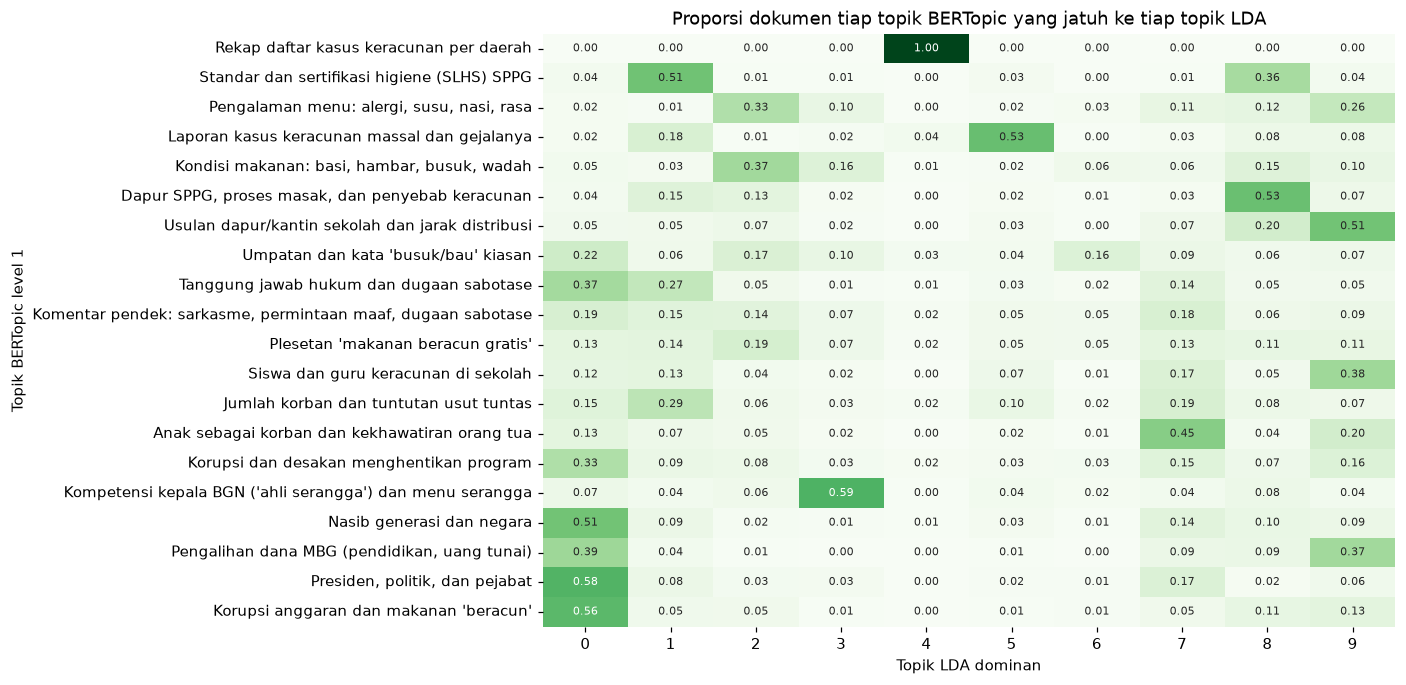

In [16]:
lda20, lda20_words = fit_lda(20)
cmp_rows = [
    dict(model="BERTopic level 1 (K-Means)", K=K_L1, **evaluate([topic_words(MODEL1, k) for k in range(K_L1)], COH1)),
    dict(model="LDA (K terbaik)", K=K_LDA, **evaluate(LDA_WORDS, COH1)),
    dict(model="LDA (K sama dengan BERTopic)", K=20, **evaluate(lda20_words, COH1)),
]
model_cmp = pd.DataFrame(cmp_rows)
model_cmp.to_csv(OUT / "perbandingan_bertopic_lda.csv", index=False)
display(model_cmp.round(3))
print("NMI penugasan topik BERTopic L1 vs LDA K=10:",
      round(normalized_mutual_info_score(docs["l1_topic"], docs["lda_topic"]), 3))

ct = pd.crosstab(docs["l1_label"], docs["lda_topic"], normalize="index")
ct = ct.loc[info1.sort_values(["kelompok", "n_docs"])["label"]]
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(ct, cmap="Greens", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, ax=ax)
ax.set_xlabel("Topik LDA dominan"); ax.set_ylabel("Topik BERTopic level 1")
ax.set_title("Proporsi dokumen tiap topik BERTopic yang jatuh ke tiap topik LDA")
savefig("perbandingan_bertopic_lda.png")

**Perbandingan BERTopic dan LDA:**

- **Coherence:** LDA terbaik pada K = 10. Pada K yang sama (20), coherence BERTopic lebih tinggi daripada LDA, sedangkan diversity LDA sedikit lebih tinggi.
- **Interpretabilitas:** sebagian topik LDA tetap dapat dibaca, misalnya "basi busuk ayam nasi bau sayur buah", "bakteri jam masak basi", dan "sppg dapur awas kualitas standar". Namun banyak topik LDA **mencampur** wacana yang berbeda, misalnya kata kondisi makanan bercampur dengan kata politik/anggaran dalam satu topik. Penyebabnya, LDA mengandalkan ko-okurensi kata dalam dokumen yang sangat pendek (median 12 token).
- **Kesesuaian kedua model:** secara keseluruhan rendah (NMI ≈ 0,15). Namun heatmap menunjukkan pola yang jelas. Topik BERTopic yang **spesifik** terkonsentrasi pada satu topik LDA: rekap kasus → LDA 4 (100%), dapur SPPG → LDA 8 (53%), laporan kasus → LDA 5 (53%), standar SLHS → LDA 1 dan 8, "ahli serangga" → LDA 3 (59%), dan topik politik/korupsi → LDA 0 (51–58%). Ketidaksesuaian terutama berasal dari topik **reaksi umum** yang tersebar di banyak topik LDA, karena dokumennya pendek dan kosakatanya generik. Artinya, tema-tema keamanan pangan yang menjadi fokus RQ1 konsisten antar-metode, sedangkan wacana umum memang sulit dipisahkan dengan *bag-of-words*.

Atas dasar itu, **BERTopic dipakai untuk analisis selanjutnya**, dan LDA berfungsi sebagai validasi silang bahwa tema-tema utama tidak bergantung pada satu metode.

# 5. Level 2: Jenis Permasalahan Keamanan dan Kebersihan Pangan (RQ1)

Korpus level 2 adalah dokumen dari tujuh topik level 1 kelompok **masalah keamanan & kebersihan pangan spesifik**. UMAP dihitung ulang khusus pada subset ini supaya struktur lokal antarjenis masalah lebih terlihat, dan kosakata evaluasi dibuat ulang dari subset (`min_df` 5).

In [17]:
fs_mask = (docs["l1_group"] == G_FS).values
sub = docs[fs_mask].reset_index(drop=True)
EMB2 = EMB[fs_mask]
VOCAB2, XB2 = build_vocab(sub["rq1_tokens"], min_df=5)
COH2 = Coherence(XB2, VOCAB2)
t0 = time.time()
R2 = UMAP(**UMAP_PARAMS).fit_transform(EMB2)
print(f"Korpus level 2: {len(sub):,} dokumen ({len(sub) / len(docs):.1%} dari korpus); kosakata {len(VOCAB2):,}; "
      f"UMAP {time.time() - t0:.0f} detik")
display(sub.groupby(["platform", "doc_type"]).size().rename("dokumen").to_frame())

Korpus level 2: 14,651 dokumen (24.2% dari korpus); kosakata 4,391; UMAP 7 detik


dokumen
platform doc_type         
x        post         3297
         quote         400
         reply        1191
youtube  comment      8366
         reply        1397

,K,npmi,c_v,diversity,stabilitas_ari,topik_terbesar
0,6,0.277,0.734,0.900,0.999,0.274
1,8,0.258,0.713,0.925,0.998,0.260
2,10,0.225,0.668,0.840,0.952,0.186
3,12,0.166,0.648,0.883,0.982,0.187
4,15,0.172,0.664,0.867,0.956,0.136
5,20,0.162,0.653,0.840,0.966,0.110
6,25,0.136,0.627,0.800,0.903,0.108


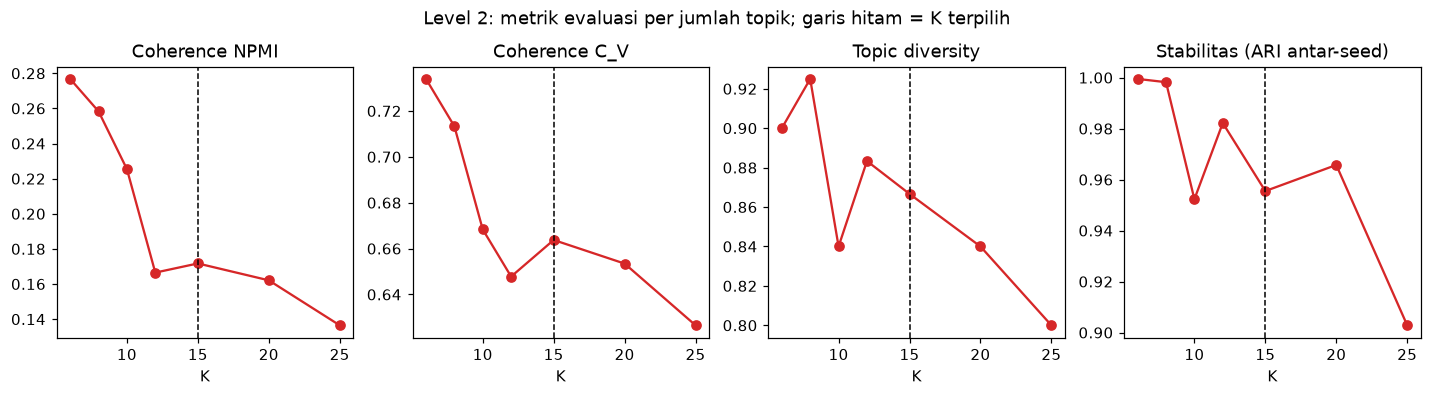

In [18]:
K_GRID_L2 = [6, 8, 10, 12, 15, 20, 25]
rows = []
for k in K_GRID_L2:
    model, t = fit_bertopic(sub["rq1_tokens"], R2, KMeans(n_clusters=k, random_state=SEED, n_init=10), VOCAB2)
    rows.append(dict(K=k, **evaluate([topic_words(model, j) for j in range(k)], COH2),
                     stabilitas_ari=kmeans_stability(R2, k, t), topik_terbesar=np.bincount(t).max() / len(t)))
grid_l2 = pd.DataFrame(rows)
grid_l2.to_csv(OUT / "l2_grid_k.csv", index=False)
display(grid_l2.round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col, title in zip(axes, ["npmi", "c_v", "diversity", "stabilitas_ari"],
                          ["Coherence NPMI", "Coherence C_V", "Topic diversity", "Stabilitas (ARI antar-seed)"]):
    ax.plot(grid_l2["K"], grid_l2[col], marker="o", color="tab:red")
    ax.axvline(15, color="black", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("K")
fig.suptitle("Level 2: metrik evaluasi per jumlah topik; garis hitam = K terpilih", y=1.04)
savefig("l2_grid_k.png")

**Justifikasi K = 15.** Coherence tertinggi ada pada K kecil (6–8). Hal ini wajar karena topik yang lebar memuat kata-kata umum yang sering muncul bersama, tetapi pada K tersebut jenis masalah yang berbeda (misalnya bakteri, jam masak, dan kebersihan dapur) masih tergabung dalam satu topik, sehingga RQ1 tidak terjawab secara rinci. Di antara K yang memisahkan jenis masalah, **K = 15 merupakan puncak lokal** NPMI dan C_V (lebih tinggi daripada K = 12 dan K = 20), dengan stabilitas antar-seed sekitar 0,96 dan diversity sekitar 0,87. Pada K = 20, topik mulai terpecah menjadi varian yang redundan, misalnya dua topik "rasa hambar" dan dua topik laporan kasus, dan stabilitasnya turun pada K = 25.

In [19]:
K_L2 = 15
MODEL2, T2 = fit_bertopic(sub["rq1_tokens"], R2, KMeans(n_clusters=K_L2, random_state=SEED, n_init=10), VOCAB2)
info2 = topic_table(MODEL2, T2, sub, COH2)
print("Evaluasi model level 2:", {k: round(v, 3) for k, v in evaluate([topic_words(MODEL2, k) for k in range(K_L2)], COH2).items()})
info2.round(3)

Evaluasi model level 2: {'npmi': np.float64(0.172), 'c_v': np.float64(0.664), 'diversity': 0.867}


,topic,n_docs,share,share_x,npmi,c_v,top_words
0,0,1991,0.136,0.862,0.393,0.894,september duga siswa alami jabar santap korban usai jateng gejala
1,1,1823,0.124,0.187,0.113,0.588,dapur bersih cuci masak higienis bahan kotor kerja punya racun
2,2,1727,0.118,0.145,0.096,0.523,hambar plastik rasa micin enak syukur basi garam pakai kasih
3,3,1641,0.112,0.274,0.146,0.654,sekolah kantin dapur masak masing jepang jam kelola pihak murid
4,4,1463,0.100,0.187,0.174,0.705,anak sekolah tua uang murid kasih guru bawa biar baik
5,5,1196,0.082,0.156,0.164,0.667,anak kasih enak hambar rasa suka tua bilang syukur uang
6,6,1178,0.080,0.755,0.386,0.908,sppg pangan standar nasional layan penuh bgn aman sanitasi perintah
7,7,973,0.066,0.099,0.191,0.709,jam masak malam pagi siang panas basi tani masakan hari
8,8,632,0.043,0.519,0.419,0.916,bakteri coli nitrit suhu salmonella kontaminasi cereus lab bacillus kandung
9,9,599,0.041,0.182,0.183,0.681,sayur buah telur telor pisang busuk salad mentah sapi jeruk


In [20]:
rep2 = print_representatives(MODEL2, T2, EMB2, sub["rq1_text_light"].values)


### Topik 0 (n=1,991)
    kata: september duga siswa alami jabar santap korban usai jateng gejala
    [centroid] kata istana soal puluhan siswa sd di sukoharjo diduga keracunan usai santap mbg
    [centroid] colokin nih ke mata kepala bgn biar tidak asa njeplak moncongnya! terjadi lagi, 25 siswa dan guru di bogor diduga keracunan mbg sebanyak 25 orang siswa dan guru sd ciherang 01, kecamatan kecamatan dramaga, bogor, jawa barat, diduga keracunan setelah …
    [centroid] baca selengkapnya: ratusan siswa sd di cawas, klaten, diduga keracunan mbg hingga tiga siswa dirawat. kepala dinkes klaten anggit budiarto menyebut sppg dihentikan sementara untuk investigasi. rk keracunan mbg
    [centroid] ternyata ratusan siswa yang diduga keracunan mbg di surabaya... mual dan muntah-muntah, ratusan siswa di surabaya diduga keracunan mbg ratusan siswa dari berbagai tingkatan sekolah mendadak dilarikan ke puskesmas dan ke rumah sakit ibu dan anak di dupak, …
    [acak] ya allah apa harus ada yang men

## 5.1. Label Manual Level 2 dan Pengelompokan Jenis Permasalahan

Setiap topik diberi label dari kata dan dokumen representatif, lalu topik yang membahas aspek serupa digabung menjadi **jenis permasalahan**. Penggabungan didasarkan pada titik terjadinya masalah dalam rantai penyediaan makanan: bahan → jam masak dan pengiriman → kebersihan dapur → temuan bakteri → gejala korban → pengawasan.

In [21]:
J_CASE = "Kasus keracunan massal & gejala korban"
J_SPOIL = "Makanan basi, busuk, atau mentah"
J_PROC = "Jam masak, pengiriman & kapasitas dapur"
J_HYG = "Kebersihan dapur & peralatan makan"
J_MICRO = "Temuan bakteri dari uji laboratorium"
J_REG = "Sertifikat & pengawasan dapur (SLHS)"
J_ALLERGY = 'Alergi & perdebatan klaim "alergi massal"'
J_SENS = "Rasa tidak enak & makanan tidak dimakan"
JENIS = [J_CASE, J_SPOIL, J_PROC, J_HYG, J_MICRO, J_REG, J_ALLERGY, J_SENS]

L2_LABELS = {
    0: ("Laporan kasus keracunan massal (siswa, gejala, penanganan)", J_CASE, "duga"),
    1: ("Kebersihan dapur, pencucian alat, dan pekerja", J_HYG, "bersih"),
    2: ("Rasa hambar, wadah plastik, dan keluhan makanan tidak layak", J_SENS, "hambar"),
    3: ("Usulan dapur per sekolah/kantin dan beban distribusi", J_PROC, "kantin"),
    4: ("Siswa enggan makan, makanan terbuang, bawa bekal", J_SENS, "bawa"),
    5: ("Pengalaman anak menerima makanan basi/tidak enak (sudut pandang orang tua)", J_SENS, "enak"),
    6: ("Standar keamanan pangan, SLHS, dan respons pemerintah", J_REG, "standar"),
    7: ("Jam masak terlalu dini dan jeda waktu sebelum disantap", J_PROC, "jam"),
    8: ("Temuan bakteri (E. coli, Salmonella, B. cereus) dan hasil uji lab", J_MICRO, "bakteri"),
    9: ("Buah, sayur, dan telur busuk atau mentah", J_SPOIL, "buah"),
    10: ("Nasi dan lauk basi", J_SPOIL, "nasi"),
    11: ("Ayam, ikan, dan daging busuk/tidak segar", J_SPOIL, "ikan"),
    12: ("Alergi/intoleransi susu, bantahan klaim 'alergi massal', dan pertolongan pertama (susu, air kelapa)", J_ALLERGY, "alergi"),
    13: ("Gejala sakit perut dan respons pejabat yang meremehkan", J_CASE, "perut"),
    14: ("Rekap daftar kasus keracunan per daerah", J_CASE, "tulungagung"),
}
check_labels(MODEL2, T2, L2_LABELS)

sub["l2_topic"] = T2
sub["l2_label"] = sub["l2_topic"].map(lambda k: L2_LABELS[k][0])
sub["jenis_masalah"] = sub["l2_topic"].map(lambda k: L2_LABELS[k][1])
info2["label"] = info2["topic"].map(lambda k: L2_LABELS[k][0])
info2["jenis_masalah"] = info2["topic"].map(lambda k: L2_LABELS[k][1])
info2.to_csv(OUT / "l2_info_topik.csv", index=False)
rep2.assign(label=rep2["topic"].map(lambda k: L2_LABELS[k][0])).to_csv(OUT / "l2_dokumen_representatif.csv", index=False)
info2[["topic", "label", "jenis_masalah", "n_docs", "share", "share_x", "npmi", "c_v", "top_words"]].round(3)

OK: 15 label manual cocok dengan kata jangkar masing-masing topik.


,topic,label,jenis_masalah,n_docs,share,share_x,npmi,c_v,top_words
0,0,"Laporan kasus keracunan massal (siswa, gejala, penanganan)",Kasus keracunan massal & gejala korban,1991,0.136,0.862,0.393,0.894,september duga siswa alami jabar santap korban usai jateng gejala
1,1,"Kebersihan dapur, pencucian alat, dan pekerja",Kebersihan dapur & peralatan makan,1823,0.124,0.187,0.113,0.588,dapur bersih cuci masak higienis bahan kotor kerja punya racun
2,2,"Rasa hambar, wadah plastik, dan keluhan makanan tidak layak",Rasa tidak enak & makanan tidak dimakan,1727,0.118,0.145,0.096,0.523,hambar plastik rasa micin enak syukur basi garam pakai kasih
3,3,Usulan dapur per sekolah/kantin dan beban distribusi,"Jam masak, pengiriman & kapasitas dapur",1641,0.112,0.274,0.146,0.654,sekolah kantin dapur masak masing jepang jam kelola pihak murid
4,4,"Siswa enggan makan, makanan terbuang, bawa bekal",Rasa tidak enak & makanan tidak dimakan,1463,0.100,0.187,0.174,0.705,anak sekolah tua uang murid kasih guru bawa biar baik
5,5,Pengalaman anak menerima makanan basi/tidak enak (sudut pandang orang tua),Rasa tidak enak & makanan tidak dimakan,1196,0.082,0.156,0.164,0.667,anak kasih enak hambar rasa suka tua bilang syukur uang
6,6,"Standar keamanan pangan, SLHS, dan respons pemerintah",Sertifikat & pengawasan dapur (SLHS),1178,0.080,0.755,0.386,0.908,sppg pangan standar nasional layan penuh bgn aman sanitasi perintah
7,7,Jam masak terlalu dini dan jeda waktu sebelum disantap,"Jam masak, pengiriman & kapasitas dapur",973,0.066,0.099,0.191,0.709,jam masak malam pagi siang panas basi tani masakan hari
8,8,"Temuan bakteri (E. coli, Salmonella, B. cereus) dan hasil uji lab",Temuan bakteri dari uji laboratorium,632,0.043,0.519,0.419,0.916,bakteri coli nitrit suhu salmonella kontaminasi cereus lab bacillus kandung
9,9,"Buah, sayur, dan telur busuk atau mentah","Makanan basi, busuk, atau mentah",599,0.041,0.182,0.183,0.681,sayur buah telur telor pisang busuk salad mentah sapi jeruk


,dokumen,proporsi,topik
jenis_masalah,,,
Kasus keracunan massal & gejala korban,2189,0.149,"0, 13, 14"
"Makanan basi, busuk, atau mentah",1552,0.106,"9, 10, 11"
"Jam masak, pengiriman & kapasitas dapur",2614,0.178,"3, 7"
Kebersihan dapur & peralatan makan,1823,0.124,1
Temuan bakteri dari uji laboratorium,632,0.043,8
Sertifikat & pengawasan dapur (SLHS),1178,0.080,6
"Alergi & perdebatan klaim ""alergi massal""",277,0.019,12
Rasa tidak enak & makanan tidak dimakan,4386,0.299,"2, 4, 5"


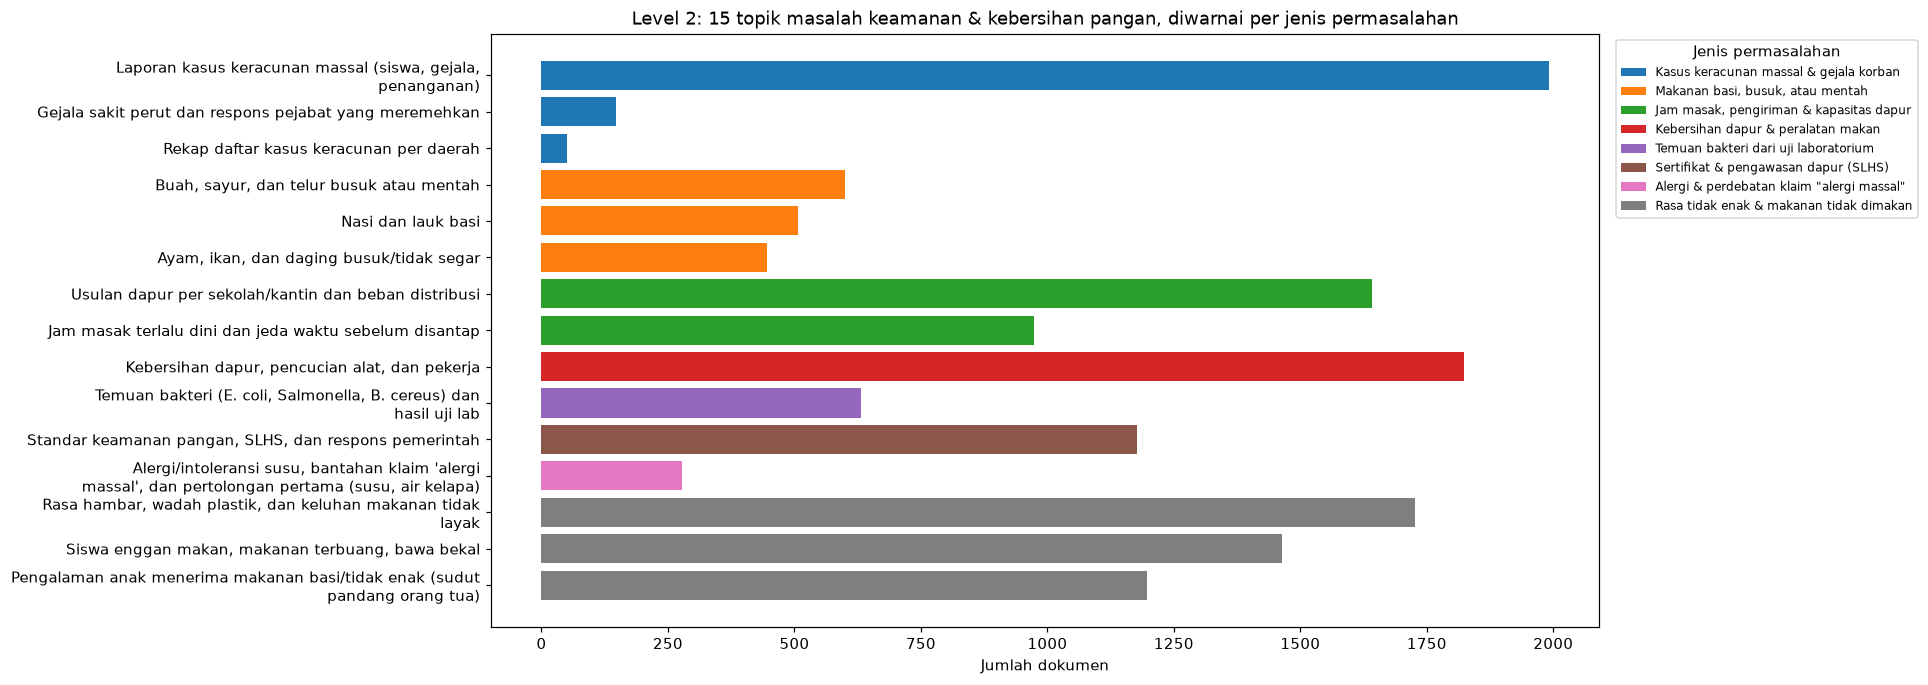

In [22]:
jen = sub["jenis_masalah"].value_counts().reindex(JENIS)
jen_tbl = pd.DataFrame({"dokumen": jen, "proporsi": (jen / jen.sum()).round(3),
                        "topik": [", ".join(str(k) for k, v in L2_LABELS.items() if v[1] == j) for j in JENIS]})
jen_tbl.to_csv(OUT / "l2_jenis_masalah.csv")
display(jen_tbl)

JCOL = dict(zip(JENIS, sns.color_palette("tab10", len(JENIS))))
plot = info2.assign(urut=info2["jenis_masalah"].map(JENIS.index)).sort_values(["urut", "n_docs"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(13, 7))
ax.barh(plot["label"].map(lambda t: textwrap.fill(t, 55)), plot["n_docs"], color=plot["jenis_masalah"].map(JCOL))
for j, c in JCOL.items():
    ax.bar(0, 0, color=c, label=j)
ax.legend(title="Jenis permasalahan", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_xlabel("Jumlah dokumen")
ax.set_title("Level 2: 15 topik masalah keamanan & kebersihan pangan, diwarnai per jenis permasalahan")
savefig("l2_topik_jenis.png")

## 5.2. Triangulasi dengan Label Lemah Berbasis Kata Kunci

`rq1_issue_categories` (dibuat saat prapemrosesan dari taksonomi kueri pengumpulan) **tidak dipakai** untuk membentuk topik. Kolom ini hanya dipakai untuk mengecek apakah topik yang ditemukan model sejalan dengan kata kunci yang dikandung dokumennya. Satu dokumen dapat memuat beberapa kategori.

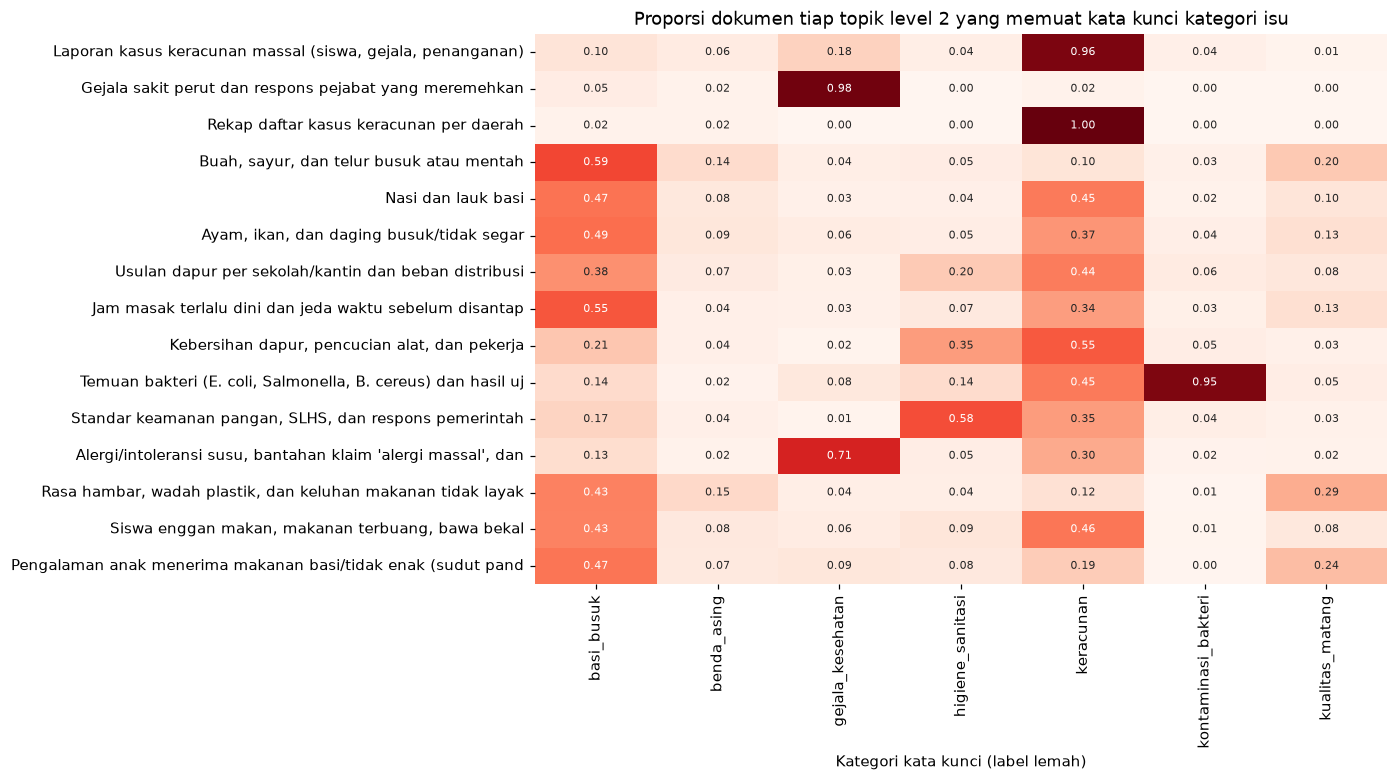

Cakupan: 43.1% dokumen yang memuat kata kunci non-'keracunan' masuk korpus level 2; sisanya ada di topik reaksi umum/politik.


In [23]:
weak = sub[["l2_label", "rq1_issue_categories"]].copy()
weak["kategori"] = weak["rq1_issue_categories"].fillna("").str.split(";")
weak = weak.explode("kategori")
weak = weak[weak["kategori"] != ""]
n_per_topic = sub["l2_label"].value_counts()
tri = (pd.crosstab(weak["l2_label"], weak["kategori"]).div(n_per_topic, axis=0)
       .loc[info2.assign(urut=info2["jenis_masalah"].map(JENIS.index)).sort_values("urut")["label"]])
tri.to_csv(OUT / "l2_triangulasi_kategori_kata_kunci.csv")
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(tri, cmap="Reds", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, ax=ax)
ax.set_yticklabels([t.get_text()[:60] for t in ax.get_yticklabels()])
ax.set_xlabel("Kategori kata kunci (label lemah)"); ax.set_ylabel("")
ax.set_title("Proporsi dokumen tiap topik level 2 yang memuat kata kunci kategori isu")
savefig("l2_triangulasi.png")

nonpois = docs["rq1_issue_categories"].fillna("").str.contains("basi_busuk|benda_asing|higiene|kontaminasi|kualitas|gejala")
print(f"Cakupan: {fs_mask[nonpois.values].mean():.1%} dokumen yang memuat kata kunci non-'keracunan' "
      f"masuk korpus level 2; sisanya ada di topik reaksi umum/politik.")

**Hasil triangulasi:**

- Topik dengan label manual spesifik sejalan dengan kata kunci yang dikandungnya: topik bakteri dengan `kontaminasi_bakteri`, topik buah/sayur, nasi, dan ayam/ikan dengan `basi_busuk`, topik kebersihan dapur dan standar dengan `higiene_sanitasi`, serta topik laporan kasus dengan `keracunan` dan `gejala_kesehatan`. Kesesuaian ini menunjukkan topik model bermakna dan bukan artefak.
- Model juga menangkap jenis masalah yang **tidak ada** dalam taksonomi kata kunci: **jam masak dan jeda distribusi** (topik ini 55% memuat kata `basi_busuk`, artinya publik mengaitkan makanan basi dengan waktu masak) dan **skala dapur serta usulan kantin sekolah**. Model juga **memisahkan** hal yang dalam taksonomi kata kunci digabung. Diskusi alergi (dalam taksonomi masuk `gejala_kesehatan`) terpisah dari laporan gejala keracunan; isinya antara lain bantahan publik atas penjelasan resmi bahwa kasus disebabkan alergi ("masa alerginya berjamaah") dan saran pertolongan pertama. Respons pejabat bahwa "hanya sakit perut biasa" juga menjadi topik sendiri. Ini nilai tambah topic modelling dibanding klasifikasi kata kunci.
- Kategori `benda_asing` (ulat, belatung, serangga, rambut, plastik) tidak membentuk topik tersendiri. Porsinya paling tinggi hanya sekitar 15% (topik buah/sayur dan topik rasa hambar/wadah plastik). Di level 1, sebagian besar penyebutan "serangga" justru berupa sindiran politik (topik "ahli serangga").
- **Cakupan:** hanya sekitar 43% dokumen yang memuat kata kunci masalah spesifik (selain "racun") masuk korpus level 2. Sisanya berada di topik reaksi umum atau politik di level 1, karena kata seperti "basi", "busuk", atau "belatung" sering dipakai sambil lalu atau secara kiasan dalam kalimat yang intinya kritik (misalnya "pejabat busuk"). Konsekuensinya, level 2 menangkap diskusi yang **substansinya** masalah pangan, bukan setiap penyebutan kata kunci. Batasan pendekatan satu-topik-per-dokumen ini dicatat di bagian keterbatasan.

# 6. Perbandingan Topik Lintas Waktu dan Platform

Rubrik meminta perbandingan topik yang bertahan lintas periode atau pengelompokan lain. Unit waktu yang dipakai adalah **bulan** (`common_year_month`, WIB). Bulan dengan kurang dari 100 dokumen ditandai karena proporsinya kurang stabil.

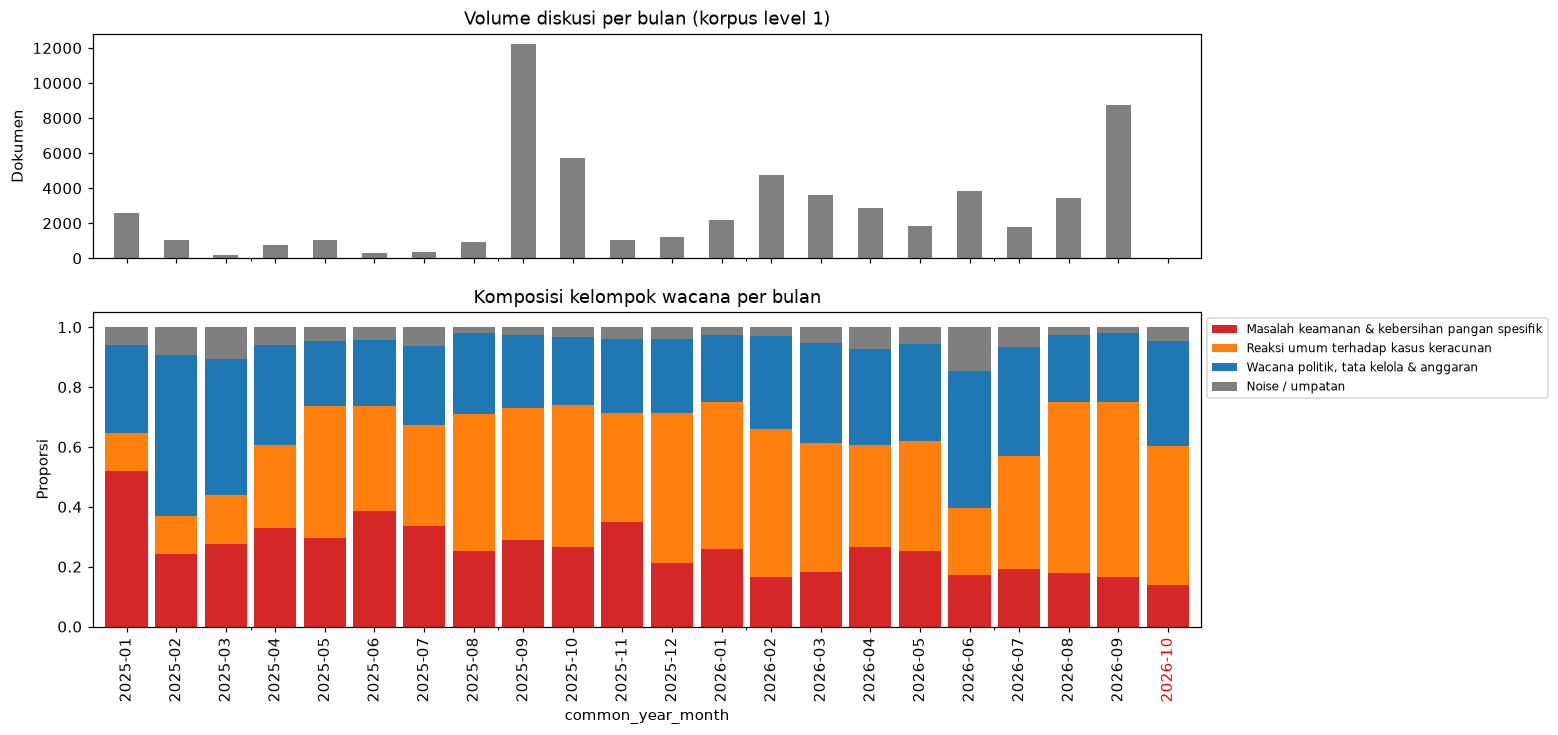

In [24]:
MIN_MONTH = 100
m1 = pd.crosstab(docs["common_year_month"], docs["l1_group"]).reindex(columns=L1_GROUPS, fill_value=0)
m1_share = m1.div(m1.sum(1), axis=0)
m1.assign(total=m1.sum(1)).to_csv(OUT / "tren_l1_kelompok_per_bulan.csv")

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
m1.sum(1).plot(kind="bar", ax=axes[0], color="gray")
axes[0].set_ylabel("Dokumen"); axes[0].set_title("Volume diskusi per bulan (korpus level 1)")
m1_share.plot(kind="bar", stacked=True, ax=axes[1], color=[colors[g] for g in L1_GROUPS], width=0.85)
axes[1].set_ylabel("Proporsi"); axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
axes[1].set_title("Komposisi kelompok wacana per bulan")
for lbl in axes[1].get_xticklabels():
    if m1.sum(1).get(lbl.get_text(), 0) < MIN_MONTH:
        lbl.set_color("red")
savefig("tren_l1_kelompok_per_bulan.png")

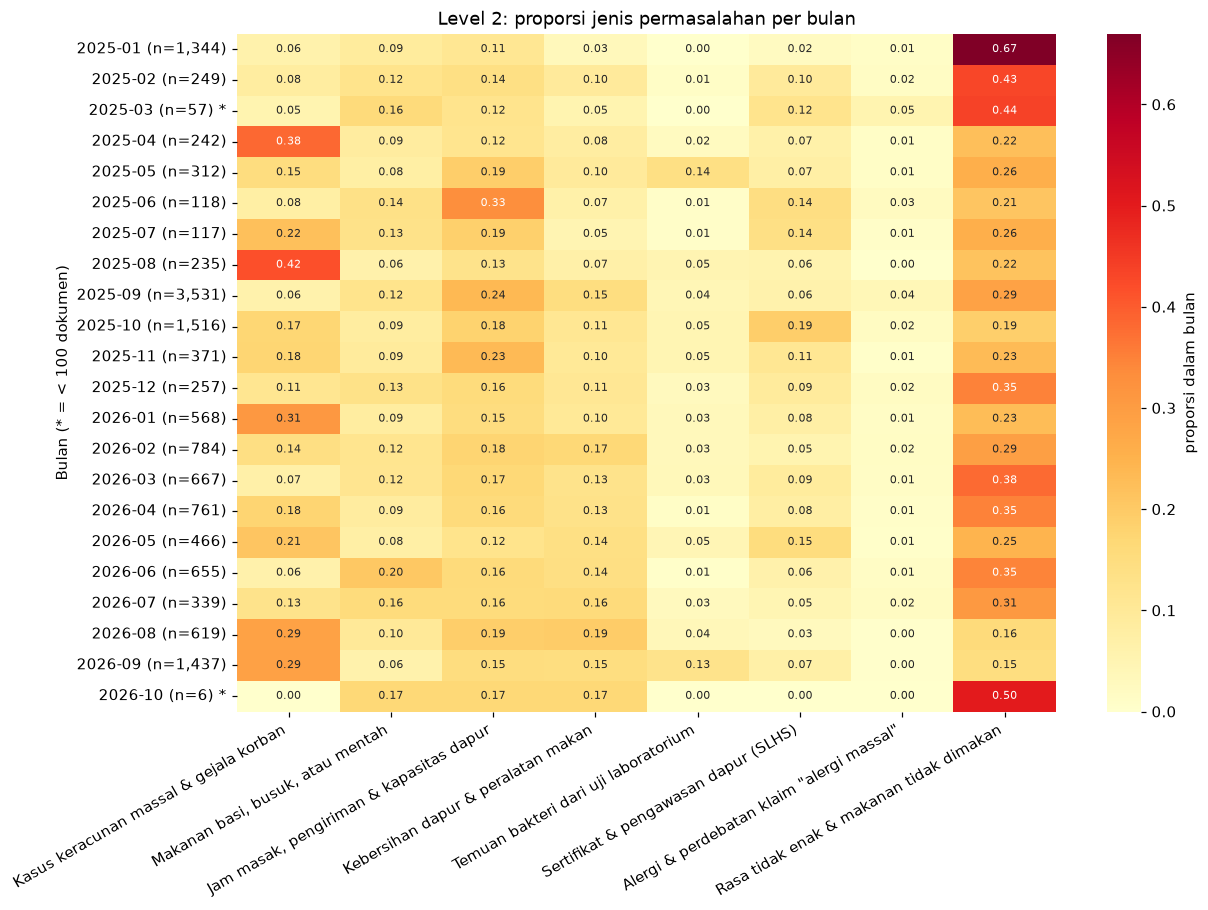

,proporsi_bulan_hadir_>=2%
jenis_masalah,
Kasus keracunan massal & gejala korban,1.0
"Makanan basi, busuk, atau mentah",1.0
"Jam masak, pengiriman & kapasitas dapur",1.0
Kebersihan dapur & peralatan makan,1.0
Temuan bakteri dari uji laboratorium,0.7
Sertifikat & pengawasan dapur (SLHS),1.0
"Alergi & perdebatan klaim ""alergi massal""",0.2
Rasa tidak enak & makanan tidak dimakan,1.0


In [25]:
m2 = pd.crosstab(sub["common_year_month"], sub["jenis_masalah"]).reindex(columns=JENIS, fill_value=0)
m2.assign(total=m2.sum(1)).to_csv(OUT / "tren_l2_jenis_per_bulan.csv")
m2_share = m2.div(m2.sum(1), axis=0)
ylabels = [f"{i} (n={n:,})" + (" *" if n < MIN_MONTH else "") for i, n in m2.sum(1).items()]
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(m2_share, cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            yticklabels=ylabels, cbar_kws={"label": "proporsi dalam bulan"})
ax.set_xticklabels([t.get_text() for t in ax.get_xticklabels()], rotation=30, ha="right")
ax.set_xlabel(""); ax.set_ylabel("Bulan (* = < 100 dokumen)")
ax.set_title("Level 2: proporsi jenis permasalahan per bulan")
savefig("tren_l2_jenis_per_bulan.png")

present = (m2_share[m2.sum(1) >= MIN_MONTH] >= 0.02).mean().rename("proporsi_bulan_hadir_>=2%")
display(present.round(2).to_frame())

**Interpretasi lintas waktu:**

- **Volume diskusi sangat dipengaruhi peristiwa.** Puncak terbesar terjadi pada **September 2025** (sekitar 12 ribu dokumen) dan **September 2026** (sekitar 8,7 ribu), bertepatan dengan gelombang kasus keracunan massal. Pada kedua puncak tersebut dan Februari 2026, porsi **reaksi umum** mencapai 44–59%, karena banyak orang bereaksi tanpa membahas rincian masalah. Sebaliknya, puncak Juni 2026 didominasi wacana politik/anggaran (46%).
- **Januari 2025 (awal program)** didominasi **rasa tidak enak dan makanan tidak dimakan** (67% dokumen level 2), yaitu perdebatan apakah menu MBG "hambar". Saat itu belum banyak kasus keracunan, sehingga topik masalah spesifik masih berupa keluhan rasa menu.
- Setelah kasus keracunan massal muncul (April–Agustus 2025), porsi **laporan kasus** naik (38–42% pada April dan Agustus 2025). Pada **September 2025** diskusi bergeser ke **penyebab di hulu**: jam masak, pengiriman, dan kapasitas dapur (24%) serta kebersihan dapur (15%). Pada **Oktober 2025**, **sertifikat dan pengawasan dapur (SLHS)** mencapai porsi tertinggi (19%), sejalan dengan kebijakan pemerintah mewajibkan SLHS bagi SPPG.
- **Temuan bakteri** muncul berupa lonjakan saat hasil uji laboratorium kasus tertentu diumumkan (14% pada Mei 2025 dan 13% pada September 2026).
- **Topik yang bertahan:** enam dari delapan jenis masalah hadir (≥ 2%) di semua bulan dengan cukup data, yaitu kasus keracunan, makanan basi/busuk, jam masak dan pengiriman, kebersihan dapur, sertifikat dan pengawasan, serta rasa tidak enak. Keenamnya merupakan keluhan **struktural** yang terus muncul sepanjang periode. Temuan bakteri (70% bulan) dan alergi (20% bulan) bersifat **episodik**.

platform                                                                       x  youtube
Level 2: jenis permasalahan Kasus keracunan massal & gejala korban         0.362    0.043
                            Makanan basi, busuk, atau mentah               0.057    0.130
                            Jam masak, pengiriman & kapasitas dapur        0.111    0.212
                            Kebersihan dapur & peralatan makan             0.070    0.152
                            Temuan bakteri dari uji laboratorium           0.067    0.031
                            Sertifikat & pengawasan dapur (SLHS)           0.182    0.030
                            Alergi & perdebatan klaim "alergi massal"      0.006    0.026
                            Rasa tidak enak & makanan tidak dimakan        0.145    0.377
Level 1: kelompok wacana    Masalah keamanan & kebersihan pangan spesifik  0.344    0.211
                            Reaksi umum terhadap kasus keracunan           0.394    0.445
                            Wacana politik, tata kelola & anggaran         0.240    0.293
                            Noise / umpatan                                0.022    0.051

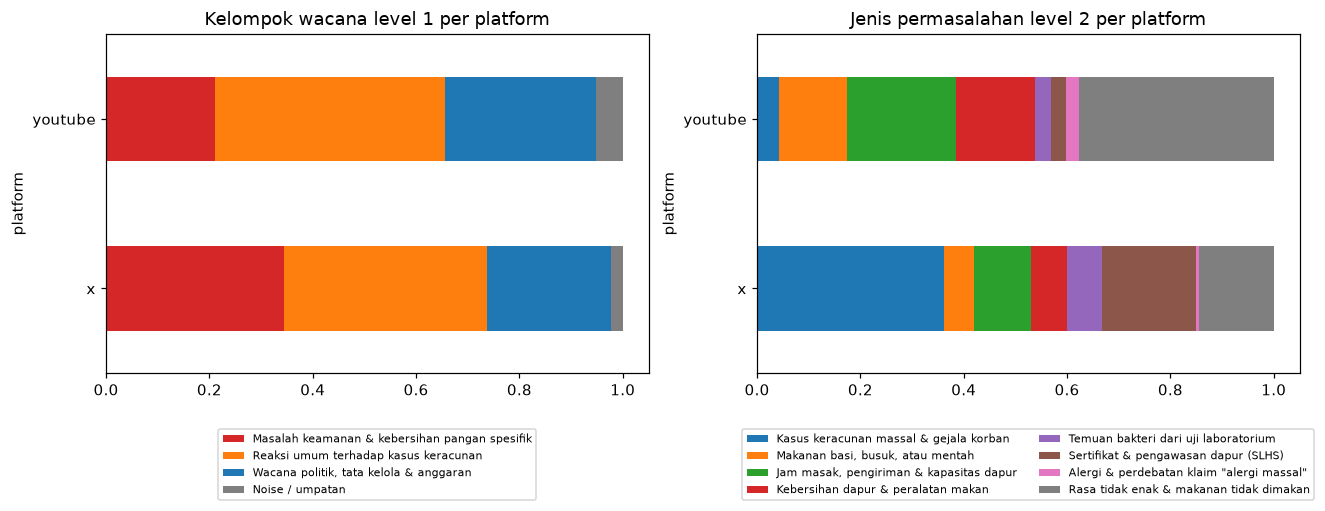

In [26]:
plat = pd.concat([
    pd.crosstab(sub["jenis_masalah"], sub["platform"], normalize="columns").reindex(JENIS),
    pd.crosstab(docs["l1_group"], docs["platform"], normalize="columns").reindex(L1_GROUPS),
], keys=["Level 2: jenis permasalahan", "Level 1: kelompok wacana"])
plat.to_csv(OUT / "perbandingan_platform.csv")
display(plat.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plat.loc["Level 1: kelompok wacana"].T.plot(kind="barh", stacked=True, ax=axes[0], color=[colors[g] for g in L1_GROUPS])
axes[0].set_title("Kelompok wacana level 1 per platform"); axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plat.loc["Level 2: jenis permasalahan"].T.plot(kind="barh", stacked=True, ax=axes[1], color=[JCOL[j] for j in JENIS])
axes[1].set_title("Jenis permasalahan level 2 per platform"); axes[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
savefig("perbandingan_platform.png")

**Interpretasi lintas platform.** Kedua platform membicarakan jenis masalah yang sama tetapi dengan **cara** yang berbeda:

- **X** lebih bersifat **informasional**. Isinya didominasi laporan kasus keracunan massal (36% dokumen level 2 di X, dibanding 4% di YouTube), sertifikat dan pengawasan SLHS (18% vs 3%), dan hasil uji bakteri (7% vs 3%). Banyak post X merupakan tautan dan ringkasan berita. Porsi masalah spesifik di X juga lebih tinggi (34% dari seluruh dokumen X, dibanding 21% di YouTube).
- **Komentar YouTube** lebih bersifat **pengalaman dan opini**: rasa tidak enak dan makanan tidak dimakan (38%), jam masak dan pengiriman (21%), kebersihan dapur (15%), makanan basi/busuk (13%), dan alergi (3%). Komentator menanggapi video kasus dengan pengalaman anaknya atau spekulasi penyebab, misalnya "masak dari jam 1 malam".

# 7. RQ2: Variasi Jenis Permasalahan Antarwilayah

Lokasi diambil dari `rq2_province`, yaitu provinsi tunggal yang disebut pada teks dokumen itu sendiri, atau **diwarisi dari konteksnya** (video atau unggahan akar yang menyebut tepat satu provinsi). Pewarisan diperlukan karena komentar YouTube jarang menyebut lokasi sendiri, padahal komentar tersebut menanggapi video tentang kasus di daerah tertentu. **Analisis utama** memakai kedua sumber lokasi. **Analisis sensitivitas** hanya memakai lokasi dari teks sendiri (`rq2_eligible_text_only`).

Uji yang dipakai:
- **Chi-square independensi** untuk menguji apakah distribusi jenis masalah berbeda antarwilayah, dengan **Cramér's V** sebagai ukuran efek.
- **Residual terstandar (adjusted)** per sel. Nilai |r| > 1,96 berarti sel tersebut secara signifikan lebih banyak (positif) atau lebih sedikit (negatif) daripada yang diharapkan bila tidak ada perbedaan antarwilayah.

In [27]:
def chi_square_report(table, name):
    table = table.loc[table.sum(1) > 0, table.sum(0) > 0]
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rs = table.sum(1).values[:, None] / n
    cs = table.sum(0).values[None, :] / n
    resid = (table - expected) / np.sqrt(expected * (1 - rs) * (1 - cs))
    print(f"{name}: χ²={chi2:,.1f}, dof={dof}, p={p:.2e}, Cramér's V={v:.3f}, n={n:,}, "
          f"sel dengan expected<5: {(expected < 5).mean():.0%}")
    return resid


def region_heatmaps(table, resid, title, fname, ylab):
    share = table.div(table.sum(1), axis=0)
    ylabels = [f"{r} (n={n:,})" for r, n in table.sum(1).items()]
    fig, axes = plt.subplots(1, 2, figsize=(18, 0.45 * len(table) + 2.5), sharey=True)
    sns.heatmap(share, cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[0],
                yticklabels=ylabels, cbar=False)
    axes[0].set_title("Proporsi jenis permasalahan dalam wilayah")
    sns.heatmap(resid, cmap="RdBu_r", center=0, vmin=-6, vmax=6, annot=True, fmt=".1f", annot_kws={"size": 7},
                ax=axes[1], cbar_kws={"label": "residual terstandar"})
    axes[1].set_title("Residual terstandar (|r| > 1,96 = signifikan)")
    for ax in axes:
        ax.set_xticklabels([t.get_text() for t in ax.get_xticklabels()], rotation=35, ha="right", fontsize=8)
        ax.set_xlabel("")
    axes[0].set_ylabel(ylab)
    fig.suptitle(title, y=1.0)
    savefig(fname)


reg = sub[sub["rq2_eligible"] == True].copy()
print(f"Dokumen level 2 berlokasi: {len(reg):,} dari {len(sub):,} ({len(reg) / len(sub):.1%}); "
      f"sumber lokasi: {reg['rq2_location_source'].value_counts().to_dict()}")

# judul video konteks, untuk menelusuri sumber lokasi warisan
VIDEO_TITLE = {}
for chunk in pd.read_csv(DATA_PATH, usecols=["doc_id", "doc_type", "text_clean"], chunksize=100_000, low_memory=False):
    v = chunk[chunk["doc_type"] == "video"]
    VIDEO_TITLE.update(zip(v["doc_id"], v["text_clean"].astype(str).str.slice(0, 110)))
print(f"Judul video konteks dimuat: {len(VIDEO_TITLE):,}")

Dokumen level 2 berlokasi: 7,804 dari 14,651 (53.3%); sumber lokasi: {'context': 5657, 'text': 2147}


Judul video konteks dimuat: 11,063


## 7.1. Per Kelompok Pulau

jenis_masalah,Kasus keracunan massal & gejala korban,"Makanan basi, busuk, atau mentah","Jam masak, pengiriman & kapasitas dapur",Kebersihan dapur & peralatan makan,Temuan bakteri dari uji laboratorium,Sertifikat & pengawasan dapur (SLHS),"Alergi & perdebatan klaim ""alergi massal""",Rasa tidak enak & makanan tidak dimakan,total
rq2_island_group,,,,,,,,,
Sumatera,207,69,150,88,51,33,7,715,1320
Jawa,1027,644,1112,815,228,331,136,1637,5930
Kalimantan,22,16,20,3,2,9,1,15,88
Sulawesi,53,15,24,18,3,14,2,43,172
Bali dan Nusa Tenggara,63,20,24,13,3,12,1,51,187
Maluku,4,2,1,1,1,1,1,2,13
Papua,42,8,14,6,1,6,1,16,94


Pulau (n ≥ 30): χ²=536.3, dof=35, p=5.15e-91, Cramér's V=0.117, n=7,791, sel dengan expected<5: 17%


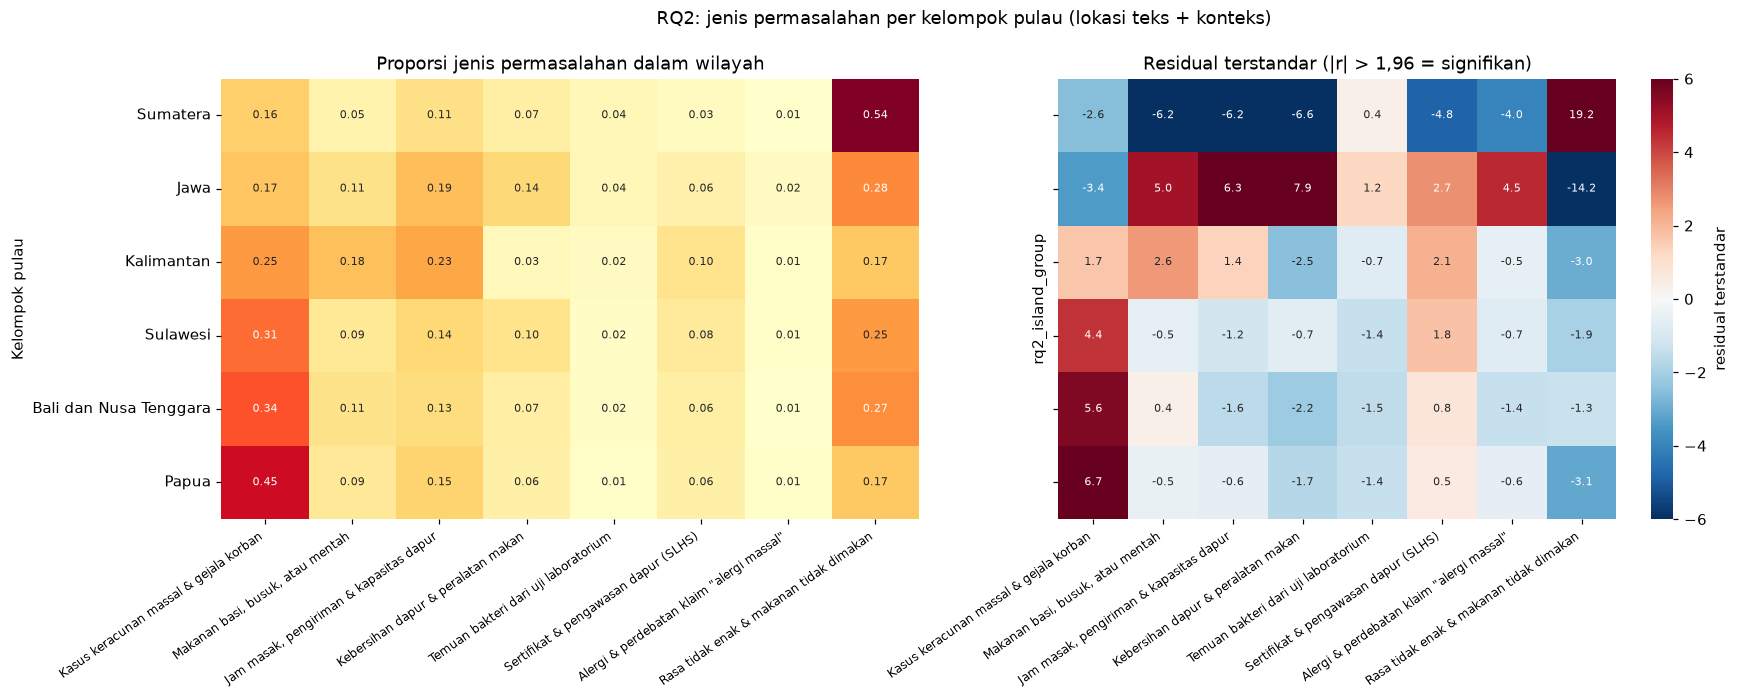

In [28]:
ISLAND_ORDER = ["Sumatera", "Jawa", "Kalimantan", "Sulawesi", "Bali dan Nusa Tenggara", "Maluku", "Papua"]
isl = pd.crosstab(reg["rq2_island_group"], reg["jenis_masalah"]).reindex(index=ISLAND_ORDER, columns=JENIS).fillna(0).astype(int)
isl.to_csv(OUT / "rq2_jenis_per_pulau.csv")
display(isl.assign(total=isl.sum(1)))
isl_test = isl[isl.sum(1) >= 30]
resid_isl = chi_square_report(isl_test, "Pulau (n ≥ 30)")
resid_isl.round(2).to_csv(OUT / "rq2_residual_pulau.csv")
region_heatmaps(isl_test, resid_isl, "RQ2: jenis permasalahan per kelompok pulau (lokasi teks + konteks)",
                "rq2_jenis_per_pulau.png", "Kelompok pulau")

**Interpretasi per pulau (unit dokumen):**

- **Jawa** menyumbang 76% dokumen level 2 yang berlokasi (5.930 dari 7.804), sehingga wilayah lain memiliki data jauh lebih sedikit dan perlu dibaca lebih hati-hati.
- Distribusi jenis masalah **berbeda signifikan** antarpulau (p < 0,001), tetapi **ukuran efeknya kecil** (Cramér's V ≈ 0,12). Delapan jenis masalah muncul di semua pulau; yang berbeda adalah **porsinya**.
- **Di luar Jawa**, diskusi lebih banyak berupa **kasus keracunan massal dan gejala korban**: 31% di Sulawesi, 34% di Bali-Nusa Tenggara, dan 45% di Papua, dibanding 17% di Jawa. Residualnya positif dan signifikan.
- **Di Jawa**, porsi masalah di **hulu** lebih tinggi secara signifikan: jam masak dan pengiriman (19%), kebersihan dapur (14%), makanan basi/busuk (11%), dan alergi (2%).
- **Sumatera** tampak didominasi keluhan rasa tidak enak (54%). Bagian 7.3 dan 7.6 menunjukkan bahwa angka ini berasal dari satu video viral.

## 7.2. Per Provinsi

9 provinsi dengan ≥ 100 dokumen mencakup 90.5% dokumen berlokasi
Provinsi lain (digabung sebagai 'Provinsi lainnya'): {'Sulawesi Selatan': 75, 'Lampung': 69, 'Nusa Tenggara Barat': 69, 'Papua': 67, 'Aceh': 63, 'Sumatera Barat': 63, 'Kalimantan Barat': 49, 'Sulawesi Tengah': 47, 'Bengkulu': 35, 'Kepulauan Riau': 32, 'Riau': 19, 'Kalimantan Timur': 18, 'Sulawesi Barat': 16, 'Gorontalo': 15, 'Jambi': 12, 'Kalimantan Selatan': 12, 'Maluku': 11, 'Papua Barat Daya': 11, 'Sulawesi Utara': 10, 'Sulawesi Tenggara': 9, 'Papua Tengah': 7, 'Bali': 6, 'Kalimantan Tengah': 6, 'Kepulauan Bangka Belitung': 5, 'Papua Barat': 4, 'Kalimantan Utara': 3, 'Papua Pegunungan': 3, 'Papua Selatan': 2, 'Maluku Utara': 2}
Provinsi (≥ 100 dokumen): χ²=1,635.5, dof=63, p=3.51e-300, Cramér's V=0.173, n=7,804, sel dengan expected<5: 6%


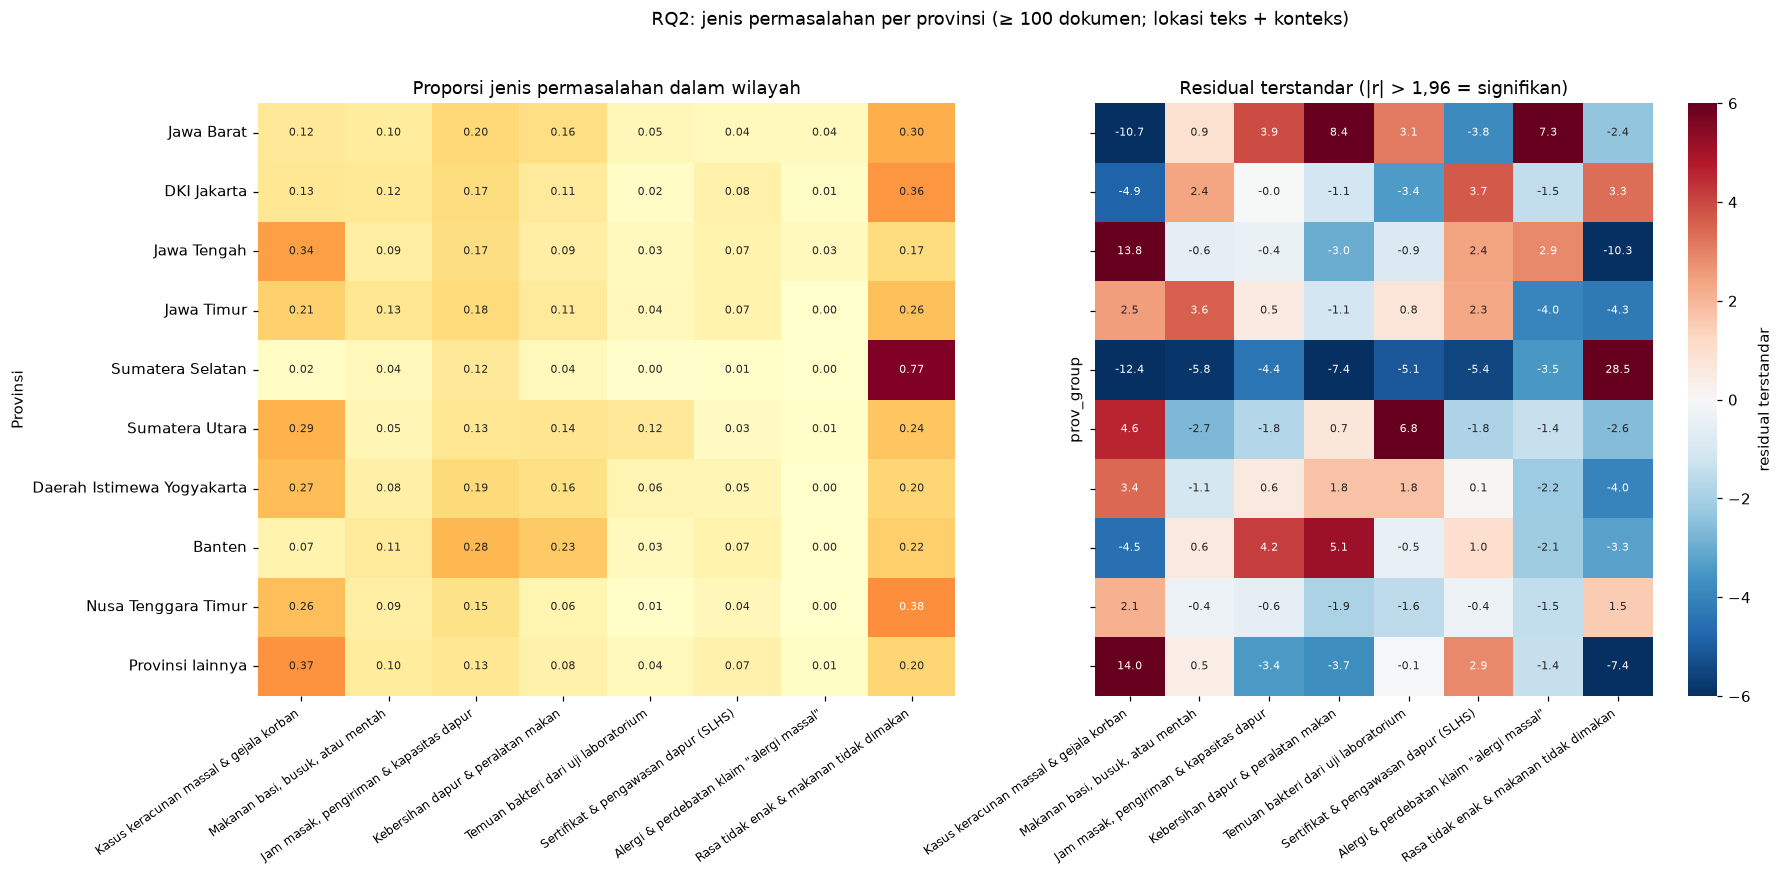

In [29]:
MIN_PROV = 100
prov_counts = reg["rq2_province"].value_counts()
PROVS = prov_counts[prov_counts >= MIN_PROV].index.tolist()
print(f"{len(PROVS)} provinsi dengan ≥ {MIN_PROV} dokumen mencakup {prov_counts[PROVS].sum() / len(reg):.1%} dokumen berlokasi")
print("Provinsi lain (digabung sebagai 'Provinsi lainnya'):", prov_counts[prov_counts < MIN_PROV].to_dict())

reg["prov_group"] = np.where(reg["rq2_province"].isin(PROVS), reg["rq2_province"], "Provinsi lainnya")
prov = pd.crosstab(reg["prov_group"], reg["jenis_masalah"]).reindex(index=PROVS + ["Provinsi lainnya"], columns=JENIS).fillna(0).astype(int)
prov.to_csv(OUT / "rq2_jenis_per_provinsi.csv")
resid_prov = chi_square_report(prov, f"Provinsi (≥ {MIN_PROV} dokumen)")
resid_prov.round(2).to_csv(OUT / "rq2_residual_provinsi.csv")
region_heatmaps(prov, resid_prov, f"RQ2: jenis permasalahan per provinsi (≥ {MIN_PROV} dokumen; lokasi teks + konteks)",
                "rq2_jenis_per_provinsi.png", "Provinsi")

**Interpretasi per provinsi (unit dokumen).** Sembilan provinsi memiliki ≥ 100 dokumen. Variasinya lebih besar daripada di tingkat pulau (Cramér's V ≈ 0,17). Kekhasan tiap provinsi, dilihat dari residual positif yang signifikan:

| Provinsi | Jenis masalah yang menonjol |
|---|---|
| Jawa Barat | Kebersihan dapur (+8,4), klaim alergi (+7,3), jam masak dan pengiriman (+3,9), temuan bakteri (+3,1); kasus keracunan massal justru lebih rendah (−10,7) |
| Jawa Tengah | Kasus keracunan massal (+13,8) |
| Jawa Timur | Makanan basi, busuk, atau mentah (+3,6), kasus keracunan massal (+2,5) |
| DKI Jakarta | Sertifikat dan pengawasan (+3,7), rasa tidak enak (+3,3), makanan basi/busuk (+2,4) |
| Banten | Kebersihan dapur (+5,1), jam masak dan pengiriman (+4,2) |
| Sumatera Utara | Temuan bakteri (+6,8), kasus keracunan massal (+4,6) |
| Sumatera Selatan | Rasa tidak enak (+28,5) |
| DI Yogyakarta | Kasus keracunan massal (+3,4) |

Bagian berikut memeriksa apakah kekhasan ini mencerminkan banyak percakapan atau hanya satu peristiwa.

## 7.3. Dokumen Representatif dan Konsentrasi Konteks untuk Sel yang Menonjol

Untuk sel provinsi × jenis masalah dengan residual positif terbesar, ditampilkan:
1. **Konsentrasi konteks:** porsi dokumen sel tersebut yang berasal dari satu konteks percakapan (video/utas) terbesar, beserta judulnya. Ini menunjukkan apakah kekhasan wilayah berasal dari banyak percakapan atau dari satu peristiwa viral.
2. **Dokumen paling dekat dengan centroid** jenis masalah tersebut di provinsi itu.

In [30]:
top_cells = (resid_prov.drop(index="Provinsi lainnya", errors="ignore").stack().sort_values(ascending=False).head(8))
cell_rows = []
for (pv, jn), r in top_cells.items():
    m = ((sub["rq2_eligible"] == True) & (sub["rq2_province"] == pv) & (sub["jenis_masalah"] == jn)).values
    idx = np.where(m)[0]
    ctx = sub.loc[idx, "context_id"].value_counts()
    c = EMB2[sub["jenis_masalah"].values == jn].mean(0)
    best = idx[np.argsort(-(EMB2[idx] @ c))[:3]]
    print(f"\n### {pv} × {jn}: residual {r:+.1f}, n={len(idx)}, {ctx.size} konteks; "
          f"konteks terbesar = {ctx.iloc[0] / len(idx):.0%} dokumen")
    print(f"    konteks terbesar: {VIDEO_TITLE.get(ctx.index[0], ctx.index[0] + ' (utas X)')}")
    for i in best:
        print(f"    [{sub.at[i, 'platform']}, lokasi dari {sub.at[i, 'rq2_location_source']}] {short(sub.at[i, 'rq1_text_light'])}")
    cell_rows.append(dict(provinsi=pv, jenis_masalah=jn, residual=r, n=len(idx), n_konteks=ctx.size,
                          porsi_konteks_terbesar=ctx.iloc[0] / len(idx),
                          konteks_terbesar=VIDEO_TITLE.get(ctx.index[0], ctx.index[0]),
                          contoh=" || ".join(sub.loc[best, "rq1_text_light"].str.slice(0, 300))))
cells_tbl = pd.DataFrame(cell_rows)
cells_tbl.to_csv(OUT / "rq2_sel_menonjol.csv", index=False)
cells_tbl[["provinsi", "jenis_masalah", "residual", "n", "n_konteks", "porsi_konteks_terbesar", "konteks_terbesar"]].round(2)


### Sumatera Selatan × Rasa tidak enak & makanan tidak dimakan: residual +28.5, n=590, 11 konteks; konteks terbesar = 82% dokumen
    konteks terbesar: Siswa SD di Palembang Kritik Menu Makan Bergizi Gratis, Rasanya Hambar | Liputan 6 Program makan bergizi grati
    [youtube, lokasi dari context] kritik rasanya hambar kok baper terus kalau anak orang tidak mampu boleh begitu dikasih makanan yang hambar
    [youtube, lokasi dari context] liatlah yang komentar.. keliatan anak orang kaya makan micin. rasanya hambar karena memang tidak pakai banyak bumbu tidak ky masakan jajanan elu cil
    [youtube, lokasi dari context] biasa makan banyak micin itu anak... mkanan sehat di bilang hambar

### Jawa Tengah × Kasus keracunan massal & gejala korban: residual +13.8, n=331, 296 konteks; konteks terbesar = 4% dokumen
    konteks terbesar: Lagi! Ratusan Siswa Diduga Keracunan MBG | Liputan 6 Ratusan siswa Madrasah Aliyah Negeri, MAN Lasem Rembang, 
    [x, lokasi dari text] kata istana soal puluha

,provinsi,jenis_masalah,residual,n,n_konteks,porsi_konteks_terbesar,konteks_terbesar
0,Sumatera Selatan,Rasa tidak enak & makanan tidak dimakan,28.46,590,11,0.82,"Siswa SD di Palembang Kritik Menu Makan Bergizi Gratis, Rasanya Hambar | Liputan 6 Program makan bergizi grati"
1,Jawa Tengah,Kasus keracunan massal & gejala korban,13.77,331,296,0.04,"Lagi! Ratusan Siswa Diduga Keracunan MBG | Liputan 6 Ratusan siswa Madrasah Aliyah Negeri, MAN Lasem Rembang,"
2,Jawa Barat,Kebersihan dapur & peralatan makan,8.37,426,140,0.36,"Lagi, Keracunan Makanan Bergizi Gratis Hebohkan Indonesia! Kali Ini Bandung Barat Jadi Sorotan Peristiwa kerac"
3,Jawa Barat,"Alergi & perdebatan klaim ""alergi massal""",7.32,91,22,0.44,"[FULL] Kasus Keracunan Makan Bergizi Gratis, Pemerintah Ungkap Penyebab-Solusi | SAPA PAGI KOMPAS.TV - Wakil M"
4,Sumatera Utara,Temuan bakteri dari uji laboratorium,6.83,30,20,0.13,Tiga Jenis Bakteri Ditemukan dalam Menu MBG Penyebab Keracunan di Karo #short Tiga Jenis Bakteri Ditemukan dal
5,Banten,Kebersihan dapur & peralatan makan,5.14,52,10,0.81,"Viral! Food Tray SPPG Lebak Dicuci Campur Limbah, Pihak Sekolah Angkat Bicara Kami memiliki rekaman video amat"
6,Sumatera Utara,Kasus keracunan massal & gejala korban,4.58,75,70,0.04,"FULL! Kasus Keracunan MBG di Karo Naik Penyidikan, Siapa Tersangka? | KOMPAS PETANG JAKARTA, KOMPASTV - Pengus"
7,Banten,"Jam masak, pengiriman & kapasitas dapur",4.16,62,38,0.37,"Viral! Food Tray SPPG Lebak Dicuci Campur Limbah, Pihak Sekolah Angkat Bicara Kami memiliki rekaman video amat"


**Pembacaan sel yang menonjol.** Ada dua tipe kekhasan wilayah:

1. **Didorong satu peristiwa viral** (satu konteks menyumbang 36–82% dokumen sel):
   - **Sumatera Selatan × rasa tidak enak:** 82% berasal dari satu video "Siswa SD di Palembang kritik menu MBG, rasanya hambar" (Januari 2025).
   - **Banten × kebersihan dapur:** 81% berasal dari video "Food tray SPPG Lebak dicuci campur limbah" (September 2025).
   - **Jawa Barat × klaim alergi:** 44% berasal dari satu video penjelasan Wamenkes tentang penyebab keracunan. Komentarnya membantah klaim "alergi" ("masa alerginya berjamaah").
   - **Jawa Barat × kebersihan dapur:** 36% berasal dari video kasus Bandung Barat.

   Sel-sel ini nyata, tetapi lebih mencerminkan **reaksi terhadap satu insiden lokal** daripada pola wilayah yang menetap.
2. **Tersebar di banyak percakapan:**
   - **Jawa Tengah × kasus keracunan massal:** 296 konteks, konteks terbesar hanya 4%. Kasusnya banyak dan berulang (Rembang, Kudus, Klaten, Sukoharjo, Grobogan, dan lain-lain).
   - **Sumatera Utara × temuan bakteri:** 20 konteks, terbesar 13%. Isinya temuan tiga jenis bakteri pada kasus Karo.

   Sel-sel ini menunjukkan karakter wilayah yang lebih kuat.

## 7.4. Komposisi Wacana Level 1 per Wilayah

Selain jenis masalah, perlu dicek apakah **porsi diskusi yang spesifik membahas keamanan pangan** juga berbeda antarwilayah. Bisa jadi di suatu wilayah diskusinya lebih banyak berupa reaksi umum atau politik.

Level 1 × pulau: χ²=470.0, dof=18, p=2.12e-88, Cramér's V=0.072, n=30,276, sel dengan expected<5: 4%


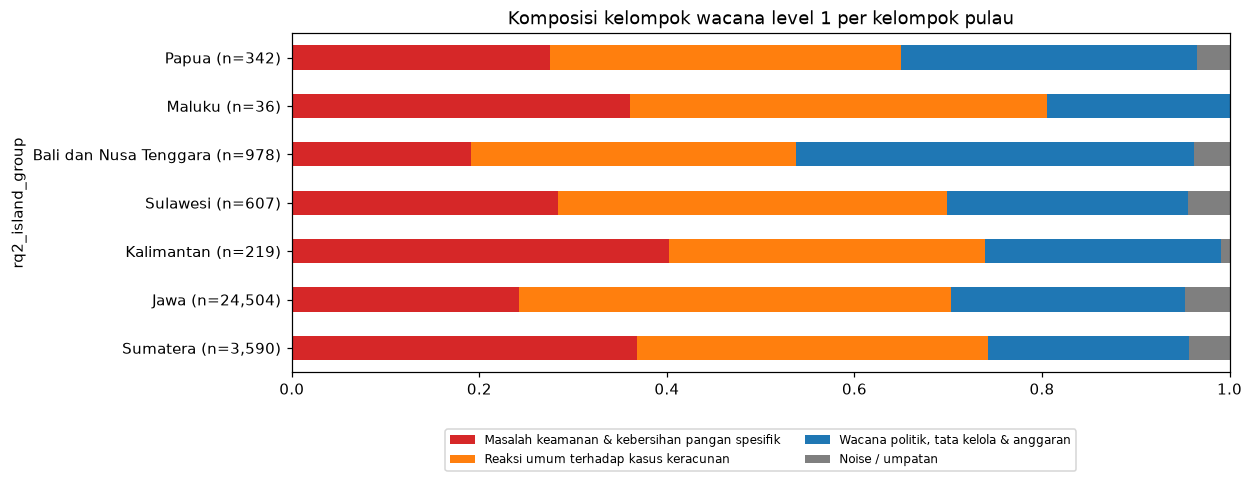

l1_group,Masalah keamanan & kebersihan pangan spesifik,Reaksi umum terhadap kasus keracunan,"Wacana politik, tata kelola & anggaran",Noise / umpatan
rq2_island_group,,,,
Sumatera,0.368,0.375,0.214,0.043
Jawa,0.242,0.461,0.250,0.047
Kalimantan,0.402,0.338,0.251,0.009
Sulawesi,0.283,0.415,0.257,0.044
Bali dan Nusa Tenggara,0.191,0.347,0.424,0.038
Maluku,0.361,0.444,0.194,0.000
Papua,0.275,0.374,0.316,0.035


In [31]:
reg1 = docs[docs["rq2_eligible"] == True]
isl1 = pd.crosstab(reg1["rq2_island_group"], reg1["l1_group"]).reindex(index=ISLAND_ORDER, columns=L1_GROUPS).fillna(0).astype(int)
isl1.to_csv(OUT / "rq2_l1_kelompok_per_pulau.csv")
resid_isl1 = chi_square_report(isl1[isl1.sum(1) >= 30], "Level 1 × pulau")
share = isl1.div(isl1.sum(1), axis=0)
ax = share.plot(kind="barh", stacked=True, figsize=(11, 4), color=[colors[g] for g in L1_GROUPS])
ax.set_yticklabels([f"{r} (n={n:,})" for r, n in isl1.sum(1).items()])
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_title("Komposisi kelompok wacana level 1 per kelompok pulau")
savefig("rq2_l1_kelompok_per_pulau.png")
display(share.round(3))

**Interpretasi.** Porsi diskusi yang membahas masalah keamanan pangan secara **spesifik** juga berbeda antarpulau (p < 0,001; V ≈ 0,07, kecil). Porsinya paling tinggi di Kalimantan (40%), Sumatera (37%), dan Maluku (36%), sedangkan Jawa 24%. Di Jawa, porsi reaksi umum terhadap kasus keracunan paling besar (46%). Hal ini sejalan dengan volume kasus dan pemberitaan yang terkonsentrasi di Jawa, yang memicu banyak komentar emosional. Bali-Nusa Tenggara memiliki porsi wacana politik/anggaran tertinggi (42%).

## 7.5. Analisis Sensitivitas: Lokasi dari Teks Sendiri Saja

Pewarisan lokasi dari konteks dapat membuat wilayah dengan video kasus besar tampak dominan. Karena itu, analisis diulang hanya pada dokumen yang **menyebut sendiri** provinsinya. Jumlah dokumennya jauh lebih kecil, sehingga analisis dilakukan per kelompok pulau.

Dokumen level 2 dengan lokasi dari teks sendiri: 2,147


jenis_masalah,Kasus keracunan massal & gejala korban,"Makanan basi, busuk, atau mentah","Jam masak, pengiriman & kapasitas dapur",Kebersihan dapur & peralatan makan,Temuan bakteri dari uji laboratorium,Sertifikat & pengawasan dapur (SLHS),"Alergi & perdebatan klaim ""alergi massal""",Rasa tidak enak & makanan tidak dimakan,total
rq2_island_group,,,,,,,,,
Sumatera,182,13,19,14,25,22,1,19,295
Jawa,851,69,149,66,101,219,5,98,1558
Kalimantan,22,2,12,2,2,9,0,7,56
Sulawesi,45,2,7,5,0,12,0,7,78
Bali dan Nusa Tenggara,48,7,10,1,1,12,1,3,83
Maluku,4,1,1,0,1,0,1,1,9
Papua,41,4,6,1,1,6,0,9,68


Pulau, lokasi teks saja (n ≥ 30): χ²=61.5, dof=35, p=3.75e-03, Cramér's V=0.076, n=2,138, sel dengan expected<5: 38%


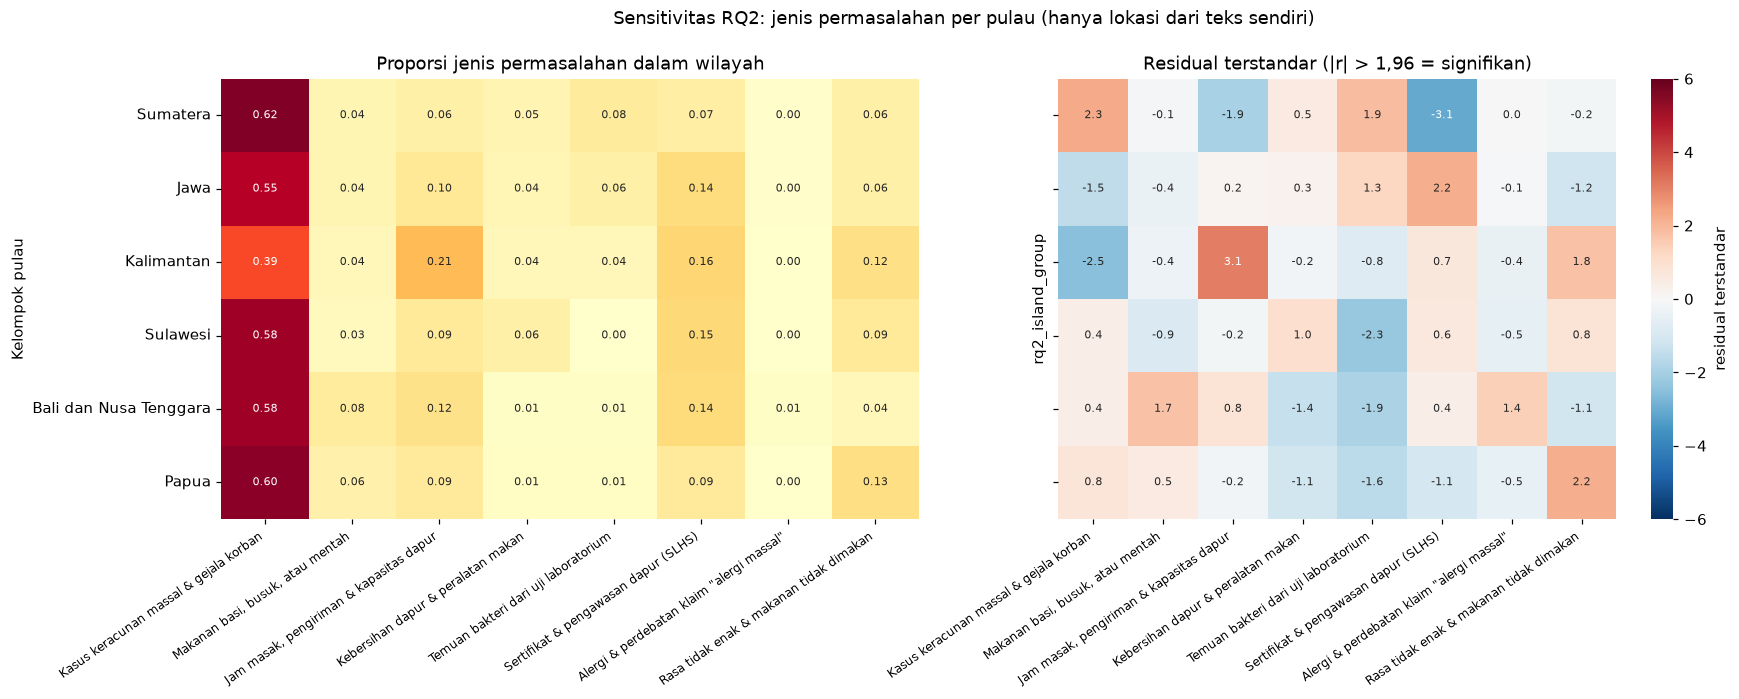

Korelasi profil jenis masalah (utama vs teks saja) per pulau:


,korelasi_profil
Sumatera,0.10
Jawa,0.25
Kalimantan,0.78
Sulawesi,0.78
Bali dan Nusa Tenggara,0.72
Papua,0.97


In [32]:
reg_txt = sub[sub["rq2_eligible_text_only"] == True]
isl_txt = pd.crosstab(reg_txt["rq2_island_group"], reg_txt["jenis_masalah"]).reindex(index=ISLAND_ORDER, columns=JENIS).fillna(0).astype(int)
isl_txt.to_csv(OUT / "rq2_sensitivitas_teks_saja_pulau.csv")
print(f"Dokumen level 2 dengan lokasi dari teks sendiri: {len(reg_txt):,}")
display(isl_txt.assign(total=isl_txt.sum(1)))
isl_txt_test = isl_txt[isl_txt.sum(1) >= 30]
resid_txt = chi_square_report(isl_txt_test, "Pulau, lokasi teks saja (n ≥ 30)")
region_heatmaps(isl_txt_test, resid_txt, "Sensitivitas RQ2: jenis permasalahan per pulau (hanya lokasi dari teks sendiri)",
                "rq2_sensitivitas_teks_saja_pulau.png", "Kelompok pulau")

both = isl_test.index.intersection(isl_txt_test.index)
corr = pd.Series({i: np.corrcoef(isl_test.loc[i] / isl_test.loc[i].sum(), isl_txt_test.loc[i] / isl_txt_test.loc[i].sum())[0, 1]
                  for i in both}, name="korelasi_profil")
print("Korelasi profil jenis masalah (utama vs teks saja) per pulau:")
display(corr.round(2).to_frame())

**Interpretasi sensitivitas lokasi teks saja.** Dengan hanya memakai lokasi yang disebut di teks sendiri (2.147 dokumen), profil semua pulau bergeser ke **laporan kasus** (39–62%). Ini karena dokumen yang menyebut lokasi sendiri kebanyakan berupa post X bergaya berita ("… siswa di Kabupaten X diduga keracunan …"). Korelasi profil dengan analisis utama tinggi untuk Papua, Sulawesi, Kalimantan, dan Bali-NT (0,72–0,97), tetapi rendah untuk Jawa (0,25) dan Sumatera (0,10). Rendahnya korelasi di Jawa dan Sumatera disebabkan komentar YouTube (yang lokasinya diwarisi dari video) membahas penyebab, rasa, dan kebersihan, sedangkan teks yang menyebut lokasinya sendiri cenderung berupa laporan. Kedua sumber lokasi menangkap **sisi berbeda** dari diskusi, sehingga kesimpulan RQ2 hanya diambil dari pola yang konsisten di keduanya. Uji chi-square tetap signifikan (p ≈ 0,004), tetapi efeknya kecil (V ≈ 0,08), dan 38% sel memiliki frekuensi harapan < 5, sehingga hasil ini bersifat indikatif.

## 7.6. Analisis Sensitivitas: Konteks Percakapan sebagai Unit

Satu video viral dapat memiliki ratusan komentar yang semuanya mewarisi lokasi video tersebut, sehingga satu peristiwa bisa mendominasi profil sebuah provinsi. Untuk mengujinya, unit analisis diubah dari **dokumen** menjadi **konteks percakapan** (video YouTube atau utas X). Setiap konteks di setiap provinsi dihitung **satu kali** dan diberi jenis masalah yang paling sering muncul di dalamnya (modus). Dengan cara ini, uji chi-square mengukur apakah variasi antarwilayah tetap ada bila setiap percakapan berbobot sama.

,dokumen,konteks,porsi_konteks_terbesar
prov_group,,,
Jawa Barat,2584,698,0.21
DKI Jakarta,998,428,0.11
Jawa Tengah,970,539,0.03
Jawa Timur,912,420,0.11
Sumatera Selatan,763,36,0.77
Sumatera Utara,259,141,0.11
Daerah Istimewa Yogyakarta,241,112,0.16
Banten,225,98,0.50
Nusa Tenggara Timur,112,60,0.29


Unit konteks: 3,066 pasangan provinsi × konteks (dari 7,804 dokumen)
Provinsi, unit = konteks: χ²=300.0, dof=63, p=1.45e-32, Cramér's V=0.118, n=3,066, sel dengan expected<5: 22%


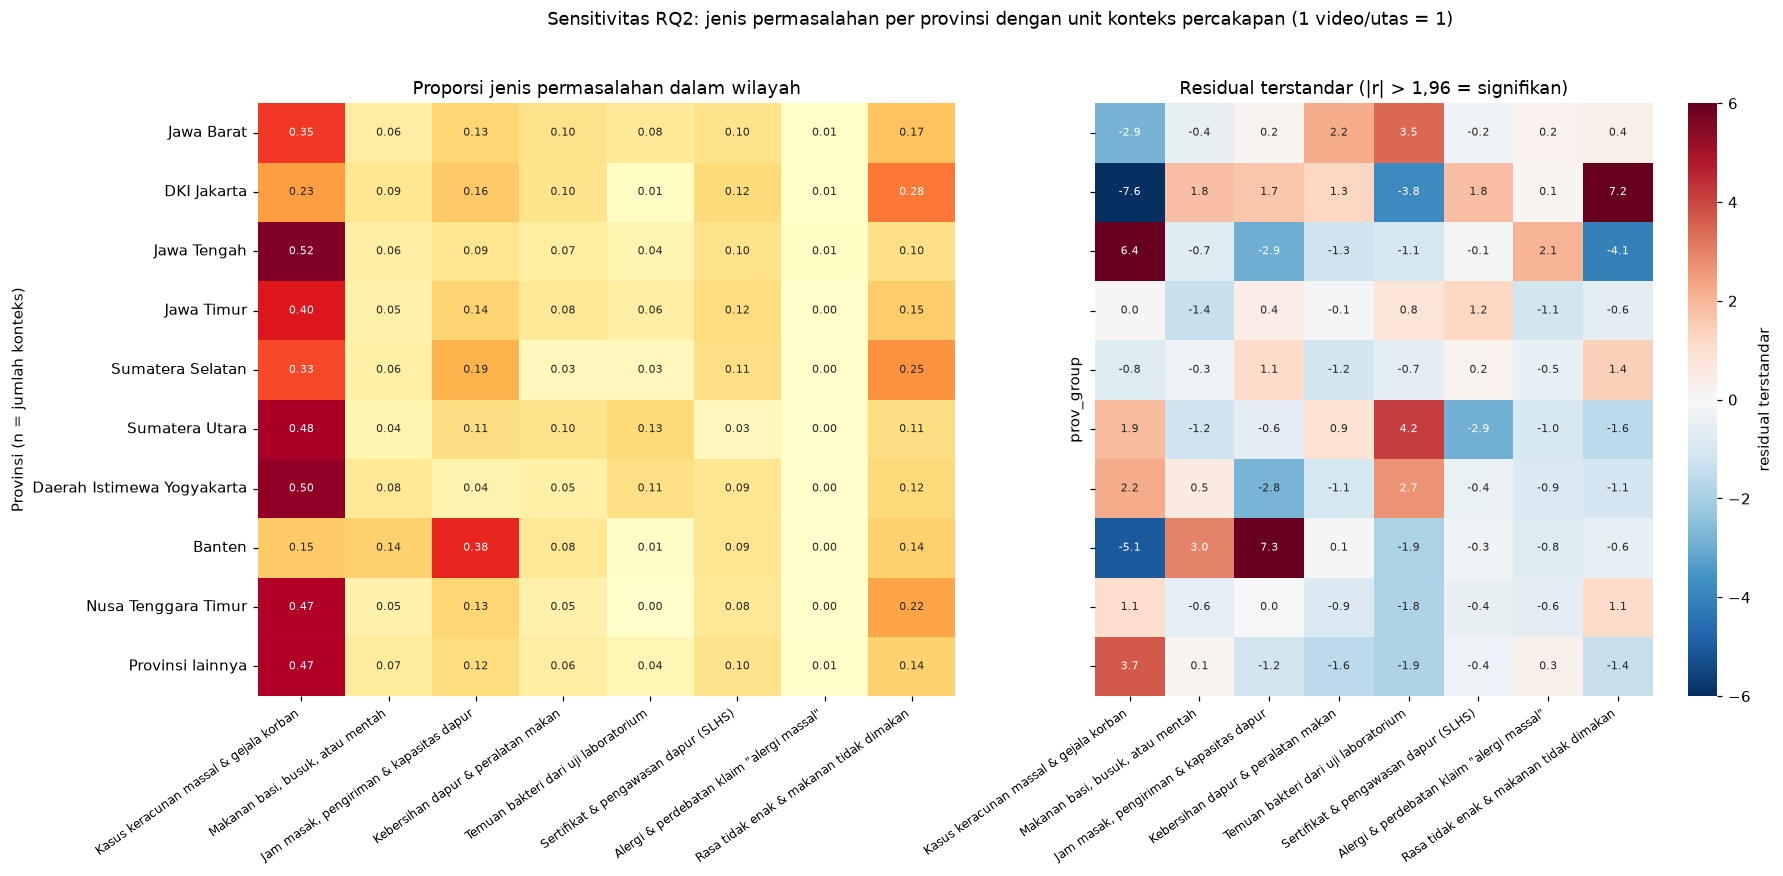

Pulau, unit = konteks (n ≥ 30): χ²=65.2, dof=35, p=1.45e-03, Cramér's V=0.065, n=3,056, sel dengan expected<5: 17%
Sel yang signifikan dan searah pada kedua unit analisis:


,,residual_dokumen,residual_konteks,konsisten,tetap_signifikan
prov_group,jenis_masalah,,,,
Banten,"Jam masak, pengiriman & kapasitas dapur",4.16,7.33,True,True
DKI Jakarta,Rasa tidak enak & makanan tidak dimakan,3.35,7.22,True,True
Jawa Tengah,Kasus keracunan massal & gejala korban,13.77,6.39,True,True
Sumatera Utara,Temuan bakteri dari uji laboratorium,6.83,4.16,True,True
Provinsi lainnya,Kasus keracunan massal & gejala korban,13.98,3.69,True,True
Jawa Barat,Temuan bakteri dari uji laboratorium,3.10,3.46,True,True
Daerah Istimewa Yogyakarta,Kasus keracunan massal & gejala korban,3.43,2.23,True,True
Jawa Barat,Kebersihan dapur & peralatan makan,8.37,2.22,True,True
Jawa Tengah,"Alergi & perdebatan klaim ""alergi massal""",2.88,2.05,True,True


In [33]:
conc = reg.groupby("prov_group").agg(dokumen=("doc_id", "size"), konteks=("context_id", "nunique"))
conc["porsi_konteks_terbesar"] = reg.groupby("prov_group")["context_id"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
conc = conc.reindex(PROVS + ["Provinsi lainnya"])
conc.to_csv(OUT / "rq2_konsentrasi_konteks_provinsi.csv")
display(conc.round(2))

ctx_level = (reg.groupby(["prov_group", "rq2_island_group", "context_id"])["jenis_masalah"]
             .agg(lambda s: s.value_counts().index[0]).rename("jenis_masalah").reset_index())
print(f"Unit konteks: {len(ctx_level):,} pasangan provinsi × konteks (dari {len(reg):,} dokumen)")

ctx_prov = pd.crosstab(ctx_level["prov_group"], ctx_level["jenis_masalah"]).reindex(
    index=PROVS + ["Provinsi lainnya"], columns=JENIS).fillna(0).astype(int)
ctx_prov.to_csv(OUT / "rq2_unit_konteks_provinsi.csv")
resid_ctx = chi_square_report(ctx_prov, "Provinsi, unit = konteks")
region_heatmaps(ctx_prov, resid_ctx, "Sensitivitas RQ2: jenis permasalahan per provinsi dengan unit konteks percakapan (1 video/utas = 1)",
                "rq2_sensitivitas_unit_konteks_provinsi.png", "Provinsi (n = jumlah konteks)")

ctx_isl = pd.crosstab(ctx_level["rq2_island_group"], ctx_level["jenis_masalah"]).reindex(
    index=ISLAND_ORDER, columns=JENIS).fillna(0).astype(int)
ctx_isl.to_csv(OUT / "rq2_unit_konteks_pulau.csv")
_ = chi_square_report(ctx_isl[ctx_isl.sum(1) >= 30], "Pulau, unit = konteks (n ≥ 30)")

persist = pd.DataFrame({"residual_dokumen": resid_prov.stack(), "residual_konteks": resid_ctx.stack()})
persist = persist[(persist["residual_dokumen"].abs() > 1.96) | (persist["residual_konteks"].abs() > 1.96)]
persist["konsisten"] = np.sign(persist["residual_dokumen"]) == np.sign(persist["residual_konteks"])
persist["tetap_signifikan"] = persist["konsisten"] & (persist["residual_konteks"].abs() > 1.96) & (persist["residual_dokumen"].abs() > 1.96)
persist.round(2).to_csv(OUT / "rq2_perbandingan_residual_dokumen_vs_konteks.csv")
print("Sel yang signifikan dan searah pada kedua unit analisis:")
persist[persist["tetap_signifikan"]].sort_values("residual_konteks", ascending=False).round(2)

**Interpretasi sensitivitas unit konteks.** Setelah setiap percakapan dihitung satu kali (3.066 konteks), variasi antarprovinsi **tetap signifikan** (p < 0,001; V ≈ 0,12, turun dari 0,17). Artinya, perbedaan antarwilayah bukan semata-mata efek satu video. Namun sebagian kekhasan memang hilang:

- **Hilang (efek satu peristiwa viral):** Sumatera Selatan × rasa tidak enak (residual turun dari +28,5 menjadi +1,4), serta sebagian besar Jawa Barat × klaim alergi dan Banten × kebersihan dapur.
- **Bertahan (signifikan dan searah di kedua unit):**
  - **Jawa Tengah → kasus keracunan massal** (+13,8 → +6,4): banyak insiden berulang di banyak kabupaten.
  - **Sumatera Utara → temuan bakteri dari uji laboratorium** (+6,8 → +4,2): kasus Karo dan temuan tiga jenis bakteri.
  - **Jawa Barat → temuan bakteri (+3,1 → +3,5) dan kebersihan dapur (+8,4 → +2,2)**: kasus Bandung Barat/Cipongkor dan temuan bakteri oleh Labkesda (Bandung Barat, Sukabumi).
  - **Banten → jam masak, pengiriman, dan kapasitas dapur** (+4,2 → +7,3): pencucian *food tray* di Lebak, makanan dalam kantong plastik di Pandeglang, dan kasus di Tangerang Selatan.
  - **DKI Jakarta → rasa tidak enak** (+3,3 → +7,2): keluhan rasa hambar pada awal program. Perlu dicatat, sebagian lokasi "DKI Jakarta" berasal dari *dateline* berita nasional ("JAKARTA, KOMPAS.TV"), sehingga provinsi ini sebagian mewakili wacana nasional.
  - **DI Yogyakarta → kasus keracunan massal** (+3,4 → +2,2).
- Di tingkat pulau, perbedaannya kecil (V ≈ 0,07). Satu-satunya pola yang konsisten di ketiga analisis (dokumen, teks saja, konteks) adalah porsi **laporan kasus yang lebih tinggi di Sulawesi, Bali-Nusa Tenggara, dan Papua** dibanding Jawa. Pada unit konteks, porsinya 41%, 50%, dan 49%, dibanding 38% di Jawa. Pola ini juga berlaku untuk Sumatera bila efek video Palembang dihilangkan (49% pada unit konteks), tetapi tidak konsisten untuk Kalimantan.

# 8. Ekspor Hasil

In [34]:
out = docs[["doc_id", "platform", "doc_type", "common_year_month", "rq2_province", "rq2_island_group",
            "l1_topic", "l1_label", "l1_group", "lda_topic"]].merge(
    sub[["doc_id", "l2_topic", "l2_label", "jenis_masalah"]], on="doc_id", how="left")
out["l2_topic"] = out["l2_topic"].astype("Int64")
# topic_label dibaca oleh analysis/sentimen/tk3_sentimen_rq3.py --topics
out["topic_label"] = out["jenis_masalah"].fillna(out["l1_group"])
assert out["doc_id"].is_unique and len(out) == len(docs)
out.to_csv(OUT / "topik_rq1.csv", index=False)

config = dict(
    dibuat_utc=pd.Timestamp.now(tz="UTC").isoformat(), dataset=str(DATA_PATH.relative_to(ROOT)),
    n_korpus_l1=len(docs), n_korpus_l2=len(sub), n_rq2_l2=len(reg), embedding_model=EMB_MODEL, umap=UMAP_PARAMS,
    clustering="KMeans(n_init=10)", seed=SEED, stability_seeds=STABILITY_SEEDS, k_l1=K_L1, k_l2=K_L2, k_lda=K_LDA,
    vocab_l1=dict(min_df=10, max_df=0.5, n=len(VOCAB1)), vocab_l2=dict(min_df=5, max_df=0.5, n=len(VOCAB2)),
    min_docs_provinsi=MIN_PROV,
    versi={m.__name__: m.__version__ for m in (pd, np, sklearn, bertopic, sentence_transformers, umap, torch)},
    python=py_platform.python_version(),
)
(OUT / "konfigurasi_run.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("Tersimpan:", sorted(p.name for p in OUT.glob("*.*")))
print("Figur    :", sorted(p.name for p in FIG.glob("*.png")))
out["topic_label"].value_counts()

Tersimpan: ['konfigurasi_run.json', 'l1_dokumen_representatif.csv', 'l1_grid_k.csv', 'l1_info_topik.csv', 'l1_perbandingan_clustering.csv', 'l2_dokumen_representatif.csv', 'l2_grid_k.csv', 'l2_info_topik.csv', 'l2_jenis_masalah.csv', 'l2_triangulasi_kategori_kata_kunci.csv', 'lda_grid_k.csv', 'lda_info_topik.csv', 'perbandingan_bertopic_lda.csv', 'perbandingan_platform.csv', 'rq2_jenis_per_provinsi.csv', 'rq2_jenis_per_pulau.csv', 'rq2_konsentrasi_konteks_provinsi.csv', 'rq2_l1_kelompok_per_pulau.csv', 'rq2_perbandingan_residual_dokumen_vs_konteks.csv', 'rq2_residual_provinsi.csv', 'rq2_residual_pulau.csv', 'rq2_sel_menonjol.csv', 'rq2_sensitivitas_teks_saja_pulau.csv', 'rq2_unit_konteks_provinsi.csv', 'rq2_unit_konteks_pulau.csv', 'topik_rq1.csv', 'tren_l1_kelompok_per_bulan.csv', 'tren_l2_jenis_per_bulan.csv']
Figur    : ['l1_grid_k.png', 'l1_topik_kelompok.png', 'l2_grid_k.png', 'l2_topik_jenis.png', 'l2_triangulasi.png', 'lda_grid_k.png', 'perbandingan_bertopic_lda.png', 'perbandin

topic_label
Reaksi umum terhadap kasus keracunan         26194
Wacana politik, tata kelola & anggaran       16957
Rasa tidak enak & makanan tidak dimakan       4386
Noise / umpatan                               2693
Jam masak, pengiriman & kapasitas dapur       2614
Kasus keracunan massal & gejala korban        2189
Kebersihan dapur & peralatan makan            1823
Makanan basi, busuk, atau mentah              1552
Sertifikat & pengawasan dapur (SLHS)          1178
Temuan bakteri dari uji laboratorium           632
Alergi & perdebatan klaim "alergi massal"      277
Name: count, dtype: int64

# 9. Jawaban Pertanyaan Penelitian

## RQ1: Jenis permasalahan keamanan dan kebersihan makanan MBG dalam diskusi media sosial

**Temuan awal (level 1).** Dari 60.495 dokumen diskusi yang relevan, hanya **24%** yang membahas masalah keamanan dan kebersihan pangan secara **spesifik**. Sisanya berupa **reaksi umum terhadap kasus keracunan** (43%: kemarahan, kekhawatiran orang tua, plesetan "makan beracun gratis", tuntutan penghentian program), **wacana politik, tata kelola, dan anggaran** (28%: korupsi, presiden, pengalihan dana, kompetensi kepala BGN), dan noise (4,5%). Artinya, kata "keracunan" yang mendominasi data lebih sering dipakai sebagai simbol kegagalan program daripada sebagai deskripsi masalah.

**Jenis permasalahan (level 2, 14.651 dokumen, 15 topik → 8 jenis):**

| # | Jenis permasalahan | Porsi | Isi utama (dari kata dan dokumen representatif) |
|---|---|---|---|
| 1 | **Rasa tidak enak & makanan tidak dimakan** | 29,9% | Rasa hambar, makanan tidak dimakan dan terbuang, siswa membawa bekal, pengalaman anak menerima makanan basi/tidak enak |
| 2 | **Jam masak, pengiriman & kapasitas dapur** | 17,8% | Masak dari tengah malam/dini hari, jeda lama hingga disantap, satu dapur melayani ribuan porsi, usulan dapur/kantin per sekolah |
| 3 | **Kasus keracunan massal & gejala korban** | 14,9% | Laporan kasus (jumlah korban, gejala mual-muntah-diare, rawat inap), rekap kasus per daerah, respons pejabat "hanya sakit perut biasa" |
| 4 | **Kebersihan dapur & peralatan makan** | 12,4% | Dapur kotor, pencucian alat/*food tray*, kebersihan pekerja, dugaan sabotase |
| 5 | **Makanan basi, busuk, atau mentah** | 10,6% | Buah, sayur, dan telur busuk/mentah; nasi dan lauk basi; ayam, ikan, dan daging tidak segar (ayam tiren, ikan hiu/histamin) |
| 6 | **Sertifikat & pengawasan dapur (SLHS)** | 8,0% | Kewajiban SLHS, HACCP, sertifikat halal, penutupan SPPG bermasalah, evaluasi pemerintah/DPR |
| 7 | **Temuan bakteri dari uji laboratorium** | 4,3% | Temuan *E. coli*, *Salmonella*, *Bacillus cereus*, nitrit, hasil uji laboratorium |
| 8 | **Alergi & perdebatan klaim "alergi massal"** | 1,9% | Alergi/intoleransi susu, bantahan atas klaim "alergi massal", saran pertolongan pertama |

**Interpretasi:**

- Permasalahan yang dibicarakan publik **mencakup seluruh rantai penyediaan makanan**, dari bahan (basi, busuk, atau mentah), jam masak dan pengiriman, kebersihan dapur, temuan bakteri, sampai gejala korban dan pengawasan.
- Jika publik membahas **penyebab**, yang paling sering disorot adalah **jam masak dan kapasitas dapur** serta **kebersihan dapur**, bukan bakteri. Temuan bakteri baru dibicarakan setelah ada hasil laboratorium.
- Jenis masalah yang ditemukan model sejalan dengan label lemah berbasis kata kunci, tetapi lebih kaya: model menemukan isu jam masak/skala dapur, klaim "alergi", dan respons pejabat yang meremehkan gejala, yang tidak ada dalam taksonomi kata kunci.
- **Lintas waktu:** pada awal program (Januari 2025) yang dominan adalah keluhan rasa. Setelah gelombang kasus pada pertengahan 2025, porsi laporan kasus naik. Pada September 2025, diskusi bergeser ke penyebab hulu (jam masak dan kebersihan dapur), lalu ke sertifikat SLHS pada Oktober 2025. Enam dari delapan jenis masalah bertahan di semua bulan, sedangkan temuan bakteri dan alergi bersifat episodik.
- **Lintas platform:** X lebih informasional (laporan kasus, standar, hasil lab), sedangkan YouTube lebih berbasis pengalaman dan opini (rasa, jam masak, kebersihan).
- **Kualitas model level 2:** NPMI 0,17, C_V 0,66, diversity 0,87, dan stabilitas antar-seed ARI ≈ 0,96. Topik dengan coherence rendah (nasi basi, ayam/ikan, alergi, sakit perut) tetap dapat diinterpretasikan dari dokumen representatifnya. Kosakatanya bervariasi (slang, ejaan tidak baku) sehingga ko-okurensi kata rendah, tetapi makna dokumennya konsisten.

## RQ2: Variasi jenis permasalahan antarwilayah

- **Jenis masalahnya sama di semua wilayah, porsinya yang berbeda.** Kedelapan jenis permasalahan muncul di semua kelompok pulau. Perbedaan distribusinya signifikan secara statistik, tetapi ukuran efeknya **kecil hingga sedang** (Cramér's V: 0,17 per provinsi dan 0,12 per pulau pada unit dokumen; 0,12 dan 0,07 pada unit konteks). Masalah keamanan pangan MBG dipersepsikan sebagai masalah **sistemik nasional**, bukan masalah daerah tertentu.
- **Kekhasan provinsi yang kuat** (bertahan di unit dokumen maupun unit konteks):
  - **Jawa Tengah:** kasus keracunan massal (banyak insiden berulang di banyak kabupaten).
  - **Jawa Barat:** temuan bakteri dan kebersihan dapur (kasus Bandung Barat/Cipongkor, temuan Labkesda).
  - **Sumatera Utara:** temuan bakteri (kasus Karo).
  - **Banten:** jam masak, pengiriman, dan kapasitas dapur (pencucian *food tray* di Lebak, kemasan plastik di Pandeglang).
  - **DKI Jakarta:** rasa tidak enak, tetapi sebagian mencerminkan wacana nasional karena *dateline* berita.
  - **DI Yogyakarta:** kasus keracunan massal.
- **Sebagian variasi bersifat sesaat, dipicu satu insiden viral.** Contohnya Sumatera Selatan × rasa hambar (satu video siswa Palembang) serta Banten × kebersihan dapur dan Jawa Barat × klaim alergi (masing-masing satu video). Variasi antarwilayah dalam diskusi publik sangat dipengaruhi oleh **insiden lokal yang diberitakan**, bukan karakter wilayah yang menetap.
- **Kesenjangan Jawa dan luar Jawa:** 76% diskusi berlokasi berasal dari Jawa. Di Jawa, diskusi lebih **mendalam soal penyebab** (jam masak, kebersihan dapur, bahan basi), sedangkan di Sulawesi, Bali-Nusa Tenggara, dan Papua diskusinya lebih banyak berupa **laporan kasus** (pola ini konsisten di ketiga analisis). Kemungkinan penyebabnya, kasus di luar Jawa lebih banyak diketahui publik lewat pemberitaan daripada lewat percakapan yang mendalam. Di sisi lain, porsi diskusi yang spesifik membahas masalah pangan justru lebih tinggi di Kalimantan dan Sumatera (36–40%) daripada di Jawa (24%), karena di Jawa diskusinya banyak berupa reaksi emosional terhadap kasus.

## Keterbatasan

1. **Satu topik per dokumen.** K-Means memberikan penugasan tegas, sehingga dokumen yang membahas beberapa masalah sekaligus disederhanakan ke topik yang paling dekat.
2. **Level 2 bergantung pada seleksi di level 1.** Hanya sekitar 43% dokumen yang memuat kata kunci masalah spesifik masuk level 2. Sisanya menyebut kata kunci secara sambil lalu dalam reaksi umum atau politik.
3. **Bias pengumpulan data.** Kueri pengumpulan berfokus pada kata "keracunan", sehingga proporsi antarjenis masalah mencerminkan diskusi yang **tertangkap kueri**, bukan seluruh diskusi MBG.
4. **Lokasi:** hanya 53% dokumen level 2 yang memiliki provinsi, dan 72% di antaranya diwarisi dari konteks. *Dateline* berita nasional dapat tercatat sebagai DKI Jakarta. Jumlah data di luar Jawa kecil, sehingga provinsi dengan < 100 dokumen digabung. Uji chi-square pada sensitivitas lokasi teks saja memiliki banyak sel dengan frekuensi harapan < 5.
5. **Evaluasi:** coherence dihitung sendiri (ko-okurensi tingkat dokumen) karena `gensim` belum tersedia untuk Python 3.15. Nilainya konsisten untuk membandingkan model dalam notebook ini, tetapi tidak identik dengan implementasi `gensim`. Stabilitas diuji antar-seed K-Means dengan proyeksi UMAP yang tetap.
6. **Label manual** dibuat oleh analis dari dokumen representatif. Untuk penguatan, label dapat divalidasi oleh anotator kedua, misalnya dengan mengukur kesepakatan pada sampel dokumen per topik.

**Keterkaitan dengan RQ3:** `hasil/topik_rq1.csv` dapat langsung dipakai oleh analisis sentimen (`python3 analysis/sentimen/tk3_sentimen_rq3.py --mode report --topics analysis/topic_modelling/hasil/topik_rq1.csv`) untuk melihat sentimen per jenis permasalahan.